# Disneyland Reviews: Text Mining & Sentiment Analysis by Rating and Park


**Authors:** 
- Izabela Kosiec 441755,
- Katarzyna Pełka 432453


## 1. Introduction

This project studies how the **language in visitor reviews** relates to the **star ratings (1–5)** given after a Disneyland visit. Star ratings are quick and easy to compare, but they often hide important details. Reviews explain *what exactly* visitors liked or disliked, for example **queues and waiting time**, **prices**, **staff experience**, **attractions**, or the overall **atmosphere**.

We focus on reviews from **three locations**: **Disneyland California**, **Disneyland Hong Kong**, and **Disneyland Paris**. The main goal is to compare these parks and check whether the same rating reflects the same type of experience across locations. In other words, we aim to identify **what people praise and complain about** at different rating levels, and whether these patterns differ between parks.

To answer this, we combine **text mining** (preprocessing, token frequency analysis, **n-grams**, and exploratory visualisations such as **word clouds**) with **sentiment analysis** using three types of methods:

- **Dictionary-based sentiment analysis (VADER)**, 
- **Machine learning models** trained on **TF–IDF features** (including **hyperparameter tuning** with **cross-validation**),  
- **A transformer-based model (BERT)**.

Because the dataset is **imbalanced** (positive reviews are much more frequent than negative and neutral), we evaluate performance using **accuracy** and **weighted F1-score**, and we also inspect **misclassified reviews** to understand where methods fail and why.

### Research Questions

- **1:** How does predicted sentiment change with rating, and does this relationship differ across Disneyland locations?  
- **2:** Which reviews show a mismatch between rating and sentiment (e.g., **5 stars but negative text**), and what do these cases look like?  
- **3:** What are the most common topics and terms in **positive** and **negative** reviews, and how do they differ across the three parks?


### Main assumptions

- **Ratings as sentiment labels:** We treat star ratings as sentiment proxies: **1–2 = negative**, **3 = neutral/mixed**, **4–5 = positive**.
- **Text reflects overall rating:** We assume the review text generally matches the rating, while allowing occasional mismatches (mixed feedback, sarcasm, strong single-issue complaints).
- **Locations are comparable:** Reviews across parks are comparable for cross-location analysis, despite differences in visitor profiles and expectations.
- **Preprocessing keeps meaning:** Cleaning/lemmatization reduces noise without removing key meaning; **negations are kept** because they can flip sentiment.
- **TF-IDF is a reasonable baseline:** Bag-of-words (with n-grams) captures enough signal for supervised sentiment baselines, even without deeper context.
- **Imbalance-aware evaluation:** Because positives dominate, we prioritize **weighted F1** alongside accuracy.
- **Train/test split estimates generalization:** A stratified split provides a reasonable proxy for out-of-sample performance of supervised models.



In [1]:
#Setup and Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer 
import pickle  
nltk.download('sentiwordnet') 
nltk.download('vader_lexicon')
from nltk.corpus import sentiwordnet as swn 
from nltk.sentiment import SentimentIntensityAnalyzer 
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from collections import Counter
from wordcloud import WordCloud
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
from nltk.util import ngrams
from sklearn.decomposition import NMF
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from transformers import pipeline

C:\Users\48661\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
[nltk_data] Downloading package sentiwordnet to
[nltk_data]     C:\Users\48661\AppData\Roaming\nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\48661\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


## 2. Data
The dataset was downloaded from Kaggle and contains Disneyland reviews with:
- `Review_ID`: unique identifier
- `Rating`: integer rating (1–5)
- `Year_Month`: year-month of the review
- `Reviewer_Location`: country/location of the reviewer
- `Review_Text`: the textual review
- `Branch`: Disneyland park (e.g., Disneyland_HongKong, Disneyland_Paris, Disneyland_California)


In [4]:
df = pd.read_csv("DisneylandReviews.csv", encoding="latin1")

print(df.shape)
df.head()


(42656, 6)


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong


In [5]:
required_cols = ["Review_Text", "Rating", "Branch"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in dataset: {missing}")

df = df.dropna(subset=required_cols).copy()
df["Review_Text"] = df["Review_Text"].astype(str)
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Rating"]).copy()
df["Rating"] = df["Rating"].astype(int)

print("Branches:", df["Branch"].unique())
df["Branch"].value_counts()


Branches: ['Disneyland_HongKong' 'Disneyland_California' 'Disneyland_Paris']


Branch
Disneyland_California    19406
Disneyland_Paris         13630
Disneyland_HongKong       9620
Name: count, dtype: int64

In [7]:
# rating 1-2 negative, 3 neutral 4-5 positive
def rating_bin(r):
    if r <= 2:
        return "negative (1-2)"
    elif r == 3:
        return "neutral (3)"
    else:
        return "positive (4-5)"

df["rating_bin"] = df["Rating"].apply(rating_bin)
df["rating_bin"].value_counts()


rating_bin
positive (4-5)    33921
neutral (3)        5109
negative (1-2)     3626
Name: count, dtype: int64

### 2.1 Distribution of rating bins

The distribution of rating bins is clearly imbalanced. The majority of reviews are positive (4–5 stars), which is typical for large tourist attractions where visitors are generally satisfied or motivated to share positive experiences. Neutral reviews (3 stars) form a much smaller group, while negative reviews (1–2 stars) represent the smallest share of the dataset.

This imbalance suggests that:
- sentiment analysis models may be biased toward positive sentiment,
- predicting neutral and negative reviews is likely to be more challenging,
- accuracy alone may be misleading, therefore macro-averaged F1 scores are used in later model evaluation.

The observed distribution also reflects real-world reviewing behavior, where extremely negative experiences are less frequent but often more emotionally expressive.


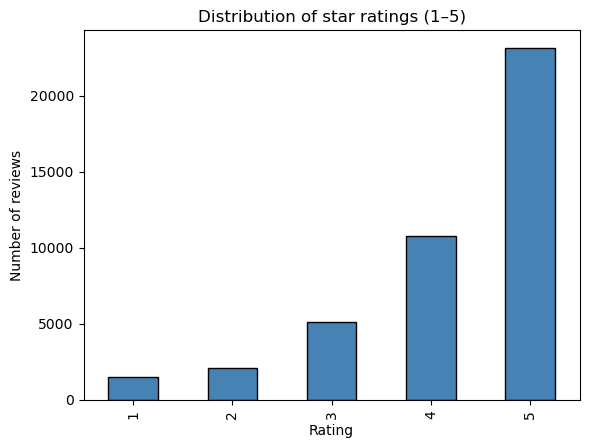

In [8]:
# Rating distribution (1–5)
df["Rating"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of star ratings (1–5)")
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.show()


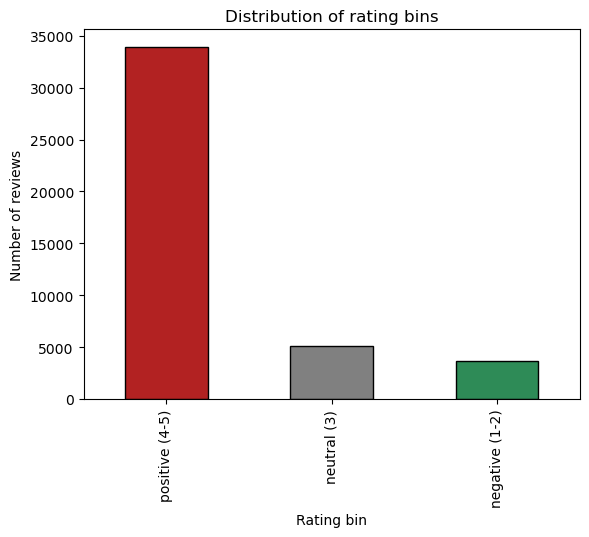

In [9]:
# Rating bin distribution
df["rating_bin"].value_counts().plot(
    kind="bar",
    color=["firebrick", "gray", "seagreen"],
    edgecolor="black"
)

plt.title("Distribution of rating bins")
plt.xlabel("Rating bin")
plt.ylabel("Number of reviews")
plt.show()


In [10]:
# Extract year from Year_Month
df["Year"] = df["Year_Month"].astype(str).str[:4]
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

df["Year"].describe()

df.groupby("Year").size()


Year
2010.0     143
2011.0    1984
2012.0    4342
2013.0    4717
2014.0    5301
2015.0    6979
2016.0    6599
2017.0    5195
2018.0    3997
2019.0     786
dtype: int64

Due to a very small number of reviews in the earliest (2010–2011) and latest (2019) years, the temporal analysis focuses on the period 2012–2018, where review volume is sufficiently large and stable to support reliable conclusions.


In [11]:
df_time = df[(df["Year"] >= 2012) & (df["Year"] <= 2018)].copy()

df_time["Year"].value_counts().sort_index()


Year
2012.0    4342
2013.0    4717
2014.0    5301
2015.0    6979
2016.0    6599
2017.0    5195
2018.0    3997
Name: count, dtype: int64

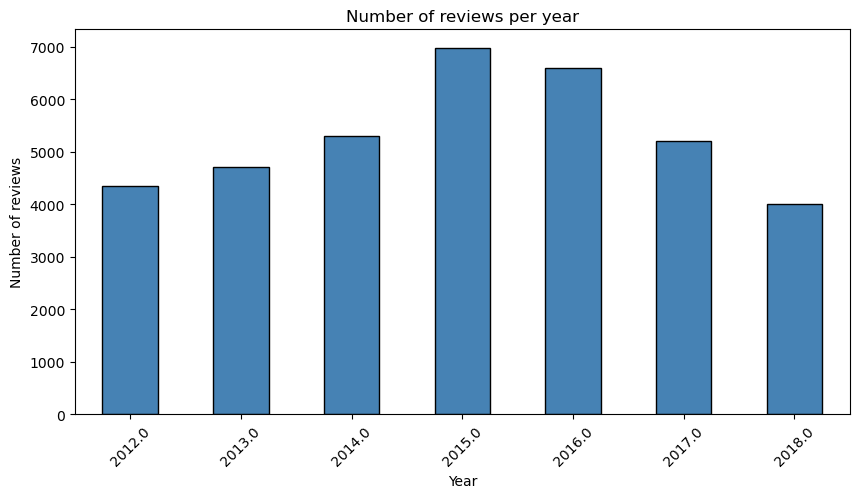

In [12]:
reviews_per_year = df_time.groupby("Year").size()

plt.figure(figsize=(10,5))
reviews_per_year.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of reviews per year")
plt.xlabel("Year")
plt.ylabel("Number of reviews")
plt.xticks(rotation=45)
plt.show()


In [13]:
df=df_time

In [14]:
sentiment_counts_branch = pd.crosstab(
    df["Branch"],
    df["rating_bin"]
)

sentiment_counts_branch


rating_bin,negative (1-2),neutral (3),positive (4-5)
Branch,,,
Disneyland_California,1056,1447,14382
Disneyland_HongKong,411,1181,6864
Disneyland_Paris,1518,1805,8466


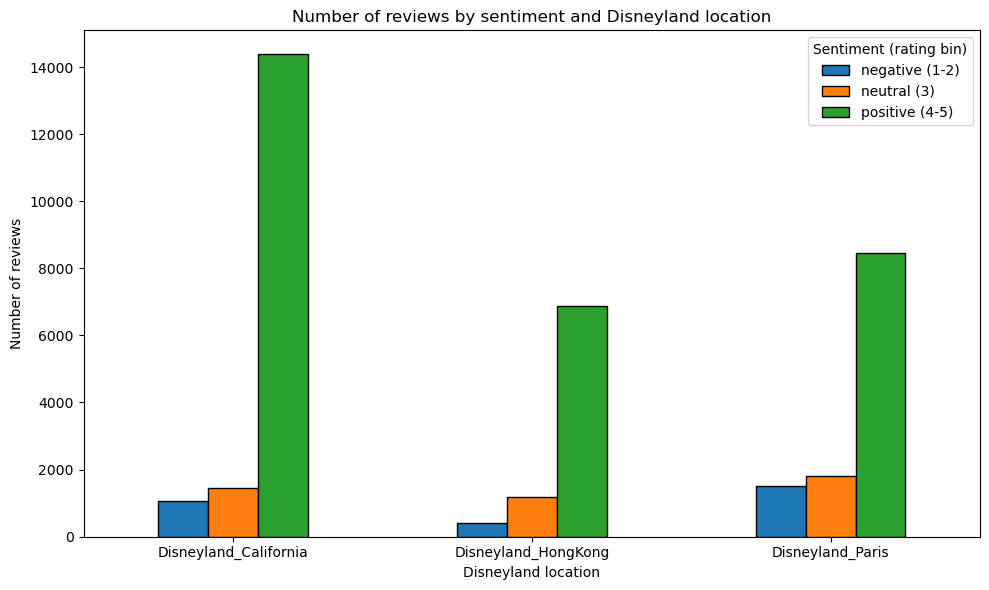

In [15]:
sentiment_counts_branch.plot(
    kind="bar",
    figsize=(10,6),
    edgecolor="black"
)

plt.title("Number of reviews by sentiment and Disneyland location")
plt.xlabel("Disneyland location")
plt.ylabel("Number of reviews")
plt.legend(title="Sentiment (rating bin)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### 2.2 Sentiment counts by location

The absolute number of reviews differs substantially across Disneyland locations. While positive reviews dominate for all parks, clear differences emerge for negative and neutral opinions.

Disneyland Paris stands out with the highest number of negative reviews, despite not having the largest overall review volume. This suggests the presence of park-specific issues or a higher tendency among visitors to express dissatisfaction. In contrast, Disneyland Hong Kong exhibits the lowest number of negative reviews, which may indicate a more consistently positive visitor experience or differences in reviewing behavior.

Neutral reviews are most frequent for Disneyland Paris, highlighting a larger share of mixed or ambivalent experiences. These findings motivate a more detailed text mining analysis of negative and neutral reviews for each location.


In [16]:
rating_counts_branch = pd.crosstab(
    df["Branch"],
    df["Rating"]
)

rating_counts_branch


Rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,409,647,1447,3493,10889
Disneyland_HongKong,138,273,1181,2840,4024
Disneyland_Paris,656,862,1805,3057,5409


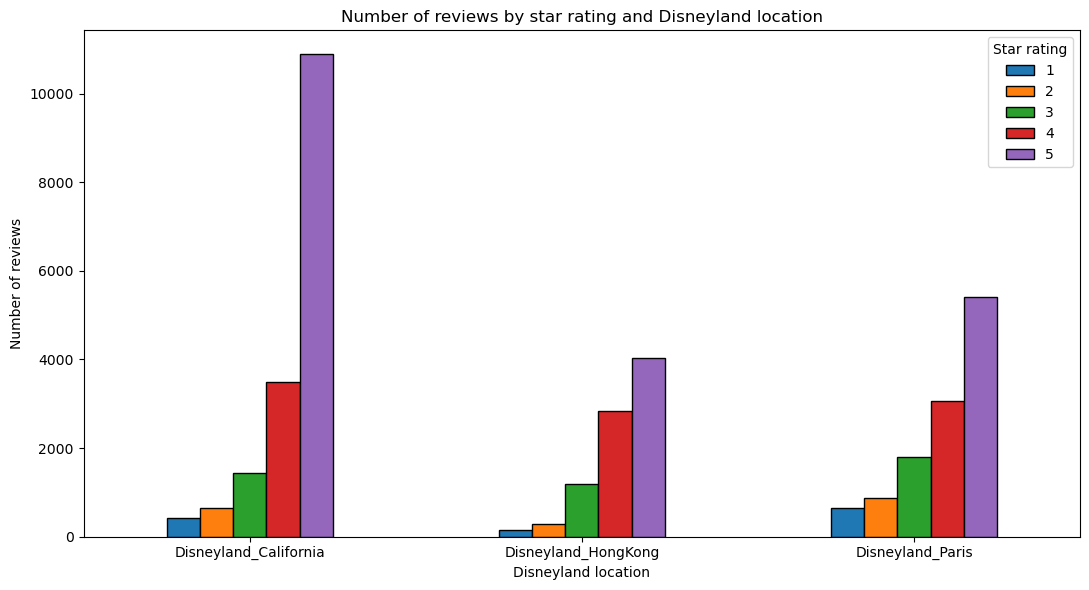

In [17]:
rating_counts_branch.plot(
    kind="bar",
    figsize=(11,6),
    edgecolor="black"
)

plt.title("Number of reviews by star rating and Disneyland location")
plt.xlabel("Disneyland location")
plt.ylabel("Number of reviews")
plt.legend(title="Star rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 2.3 Star rating distribution by location

The distribution of star ratings highlights clear differences across Disneyland locations. Disneyland California shows a strong concentration of 5-star reviews, indicating a large share of highly satisfied visitors. Disneyland Hong Kong also exhibits a predominantly positive rating structure, with relatively few 1- and 2-star reviews.

In contrast, Disneyland Paris records the highest number of 1-star and 2-star ratings, suggesting more frequent and more intense dissatisfaction. The higher presence of extreme negative ratings in Paris indicates that negative experiences are not only more common but also more severe compared to the other locations.


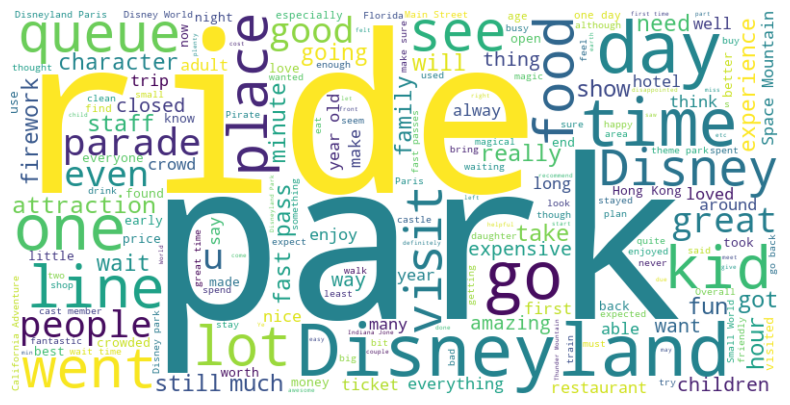

In [18]:
all_reviews = ' '.join(df['Review_Text'])

wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    max_words=200, 
    colormap='viridis', 
    contour_color='black', 
    contour_width=1
).generate(all_reviews)


plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

### 2.4 Wordcloud from reviews
This initial word cloud, generated from the raw review text (before lemmatization and other preprocessing), provides a high-level overview of the vocabulary used by visitors rather than a final interpretation. The most prominent terms (e.g., park, ride, line/queue, time/day, food, staff, ticket) suggest that reviews frequently focus on core elements of the visit experience such as attractions, waiting times, pricing/entry conditions, and service quality. At this stage, the visualization should be treated as an exploratory starting point - it highlights dominant themes in an unfiltered way, and later preprocessing will help reduce noise and reveal more informative, location- and sentiment-specific patterns.

In [20]:
# Review length before preprocessing (raw text)
df["raw_length"] = df["Review_Text"].apply(lambda x: len(x.split()))

df["raw_length"].describe()


count    37130.000000
mean       125.406949
std        147.192212
min          3.000000
25%         44.000000
50%         79.000000
75%        150.000000
max       3527.000000
Name: raw_length, dtype: float64

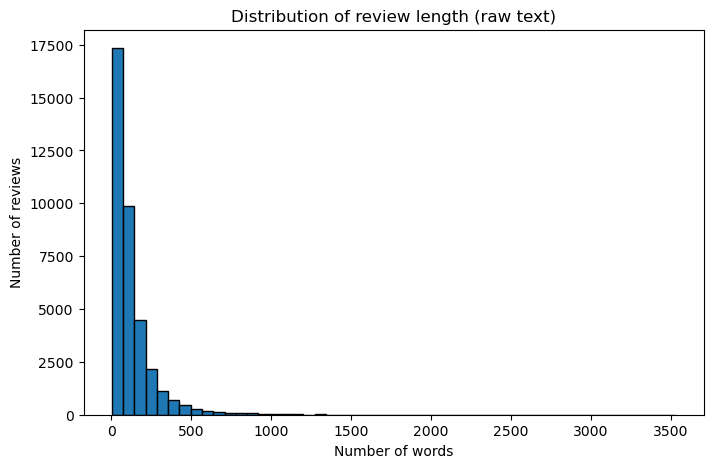

In [21]:
# Histogram of raw review length
plt.figure(figsize=(8,5))
plt.hist(df["raw_length"], bins=50, edgecolor="black")
plt.title("Distribution of review length (raw text)")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.show()


### 2.5 Review length analysis

The distribution of review length shows substantial variability across observations. Most reviews are relatively short, while a smaller number of reviews are considerably longer. This right-skewed distribution is typical for user-generated content, where visitors often provide brief opinions, while only a subset writes detailed descriptions of their experience.

Analyzing review length is important because very short reviews may contain limited semantic information, whereas longer reviews are more likely to express nuanced sentiment and multiple aspects of the visit.


## 3. TEXT PREPROCESSING

### 3.1 Text preprocessing pipeline

To improve clarity and reproducibility, a modular text preprocessing pipeline was implemented. Each step is encapsulated in a separate function, which makes the workflow transparent and allows us to inspect how individual operations affect the textual representation.

The pipeline includes:
1. **Text cleaning** (lowercasing, removal of numbers, punctuation and extra whitespace),
2. **Tokenization** using NLTK,
3. **Lemmatization** with `WordNetLemmatizer`,
4. **Stopword removal**, starting from the NLTK English stopword list and extending it with a small set of **domain-specific stopwords** (e.g., *disney*, *disneyland*, *park*). Importantly, **negation markers** (e.g., *not*, *no*, *nor* and contracted forms) are explicitly retained, as they carry crucial information for sentiment classification.

Additionally, a verbose helper function is used to track how the number of **unique tokens** changes after each step, providing a quantitative view of the impact of normalization and filtering.


In [22]:
# Text preprocessing pipeline
lemmatiser = nltk.stem.WordNetLemmatizer()
stop_words = nltk.corpus.stopwords.words('english')

def clean_text(text):
    """
    Cleans a single text string while preserving negations.
    Apostrophes are normalized BEFORE punctuation removal
    to prevent splitting contracted negations.
    """

    text = re.sub(r'\n', ' ', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'[^\x00-\x7F]+', '', text)
    text = text.lower()
    words = text.split()
    words = [word for word in words if len(word) > 1]
    text = ' '.join(words)
    return text


def tokenize_text(text):
    """Tokenizes a cleaned text."""
    return word_tokenize(text)

def lemmatize_tokens(tokens):
    """Lemmatizes a list of tokens."""
    return [lemmatiser.lemmatize(token) for token in tokens]

def count_unique_tokens(texts):
    return Counter(token for doc in texts for token in set(doc))

def process_texts_verbose(data):
    cleaned = [clean_text(text) for text in data]
    tokenized = [text.split() for text in cleaned]
    freq_cleaned = count_unique_tokens(tokenized)
    print('After cleaning:', len(freq_cleaned), 'unique tokens')

    lemmatized = [lemmatize_tokens(doc) for doc in tokenized]
    freq_lemmatized = count_unique_tokens(lemmatized)
    print('After lemmatization:', len(freq_lemmatized), 'unique tokens')

    return lemmatized



#### 3.1.1 Why lemmatization instead of stemming?

Lemmatization was chosen over stemming because it produces linguistically valid and interpretable base forms of words. Unlike stemming, which applies heuristic rules to truncate words and may generate non-words (e.g., *amazing → amaz*, *better → bett*), lemmatization maps words to their dictionary forms based on lexical knowledge.

In the context of this project, interpretability plays a crucial role. The analysis focuses on identifying meaningful keywords, themes, and complaints expressed by visitors in their reviews. Using lemmatization ensures that extracted tokens remain readable and semantically coherent, which facilitates interpretation of results in text mining tasks such as keyword analysis, thematic exploration, and topic modeling.

Moreover, lemmatization allows different grammatical forms of the same word to be merged into a single representation (e.g., *rides*, *riding* → *ride*) without losing semantic clarity. This reduces vocabulary sparsity while preserving the original meaning of the text, which is particularly important for sentiment analysis and machine learning models based on word frequencies and TF-IDF representations.

Although stemming may achieve stronger vocabulary reduction, it can distort word forms and hinder interpretability. Given the educational and analytical objectives of this project, lemmatization provides a better balance between normalization and semantic transparency.


In [23]:
df["tokens_tokenized"] = df["Review_Text"].apply(
    lambda x: tokenize_text(clean_text(x))
)

df[["Review_Text", "tokens_tokenized"]].head()


,Review_Text,tokens_tokenized
14,This place is HUGE! Definately need more than ...,"[this, place, is, huge, definately, need, more..."
19,There is nothing more to say except that you b...,"[there, is, nothing, more, to, say, except, th..."
27,We have been to Hong Kong Disneyland a few tim...,"[we, have, been, to, hong, kong, disneyland, f..."
34,"We have been to Disneyland in LA two times, an...","[we, have, been, to, disneyland, in, la, two, ..."
38,You have to visit to understand the memorable ...,"[you, have, to, visit, to, understand, the, me..."


In [24]:
df["tokens_lemmatized"] = df["tokens_tokenized"].apply(
    lambda tokens: lemmatize_tokens(tokens)
)

df[["tokens_tokenized", "tokens_lemmatized"]].head()


,tokens_tokenized,tokens_lemmatized
14,"[this, place, is, huge, definately, need, more...","[this, place, is, huge, definately, need, more..."
19,"[there, is, nothing, more, to, say, except, th...","[there, is, nothing, more, to, say, except, th..."
27,"[we, have, been, to, hong, kong, disneyland, f...","[we, have, been, to, hong, kong, disneyland, f..."
34,"[we, have, been, to, disneyland, in, la, two, ...","[we, have, been, to, disneyland, in, la, two, ..."
38,"[you, have, to, visit, to, understand, the, me...","[you, have, to, visit, to, understand, the, me..."


In [25]:
# Standard stopwords
stop_words = set(stopwords.words("english"))

# Minimal domain-specific stopwords 
domain_stopwords = {
    "disney", "disneyland", "park", "parks"
}

stop_words = stop_words.union(domain_stopwords)

print("Stopwords count (standard + domain):", len(stop_words))
print("Domain stopwords:", domain_stopwords)


Stopwords count (standard + domain): 202
Domain stopwords: {'disney', 'disneyland', 'parks', 'park'}


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\48661\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [26]:
negations_to_keep = {
    "no", "nor", "not",
    "ain", "aren", "isn", "wasn", "weren",
    "don", "doesn", "didn",
    "hasn", "haven", "hadn",
    "cant", "couldn", "won", "wouldn",
    "shouldn", "needn", "mustn"
}

stop_words = stop_words - negations_to_keep

print("Stopwords count after keeping negations:", len(stop_words))


Stopwords count after keeping negations: 182


In [27]:
# Stopwords  in our lemmatized tokens 
all_lemmas = [t for doc in df["tokens_lemmatized"] for t in doc]
lemma_counts = Counter(all_lemmas)

stopwords_in_corpus = {w for w in stop_words if w in lemma_counts}

top_removed = [(w, lemma_counts[w]) for w in stopwords_in_corpus]
top_removed = sorted(top_removed, key=lambda x: x[1], reverse=True)[:30]

print("How many stopwords are present in the corpus and would be removed:", len(stopwords_in_corpus))
print("\nTop 30 stopwords that would be removed (frequency in lemmatized tokens):")
for w, c in top_removed:
    print(f"{w:>12} : {c}")

negations_check = sorted([w for w in negations_to_keep if w in stop_words])
print("\nNegations that are STILL in stop_words (should be EMPTY):", negations_check)

def preview_removed(tokens, stop_words_set, n=50):
    removed = [t for t in tokens if t in stop_words_set]
    kept = [t for t in tokens if t not in stop_words_set]
    return removed[:n], kept[:n]

print("\n--- Examples: BEFORE/AFTER stopword removal (first 3 docs) ---")
for j, toks in enumerate(df["tokens_lemmatized"].head(3)):
    removed, kept = preview_removed(toks, stop_words)
    print(f"\nDoc {j}")
    print("Removed (sample):", removed)
    print("Kept (sample):   ", kept)



How many stopwords are present in the corpus and would be removed: 129

Top 30 stopwords that would be removed (frequency in lemmatized tokens):
         the : 259354
         and : 148161
          to : 138349
          it : 76363
          of : 75882
          we : 71852
          in : 67787
         for : 64737
          is : 59388
         you : 54714
        park : 46194
         but : 36312
        were : 35482
          at : 35349
        that : 34113
          on : 33846
         are : 33463
           a : 31999
      disney : 30922
        with : 30889
       there : 28299
  disneyland : 27878
          so : 27753
        have : 27734
        this : 25249
         all : 24979
          be : 23448
          my : 21802
         had : 21182
        they : 19068

Negations that are STILL in stop_words (should be EMPTY): []

--- Examples: BEFORE/AFTER stopword removal (first 3 docs) ---

Doc 0
Removed (sample): ['this', 'is', 'more', 'than', 'we', 'had', 'and', 'they', 'it', 'of', 

In [28]:
# List all stopwords that actually occur in the corpus and will be removed

all_lemmas = set(t for doc in df["tokens_lemmatized"] for t in doc)
removed_words = sorted(w for w in stop_words if w in all_lemmas)

print("Total number of removed words:", len(removed_words))
print("\nList of removed words (alphabetical):\n")

for w in removed_words:
    print(w)


Total number of removed words: 129

List of removed words (alphabetical):

a
about
above
after
again
against
all
am
an
and
any
are
at
be
because
been
before
being
below
between
both
but
by
can
d
did
disney
disneyland
do
doing
down
during
each
few
for
from
further
had
have
having
he
her
here
hers
herself
him
himself
his
how
i
if
in
into
is
it
itself
just
ll
m
ma
me
more
most
my
myself
now
o
of
off
on
once
only
or
other
our
ours
ourselves
out
over
own
park
re
same
shan
she
should
so
some
such
t
than
that
the
their
theirs
them
themselves
then
there
these
they
this
those
through
to
too
under
until
up
ve
very
we
were
what
when
where
which
while
who
whom
why
will
with
y
you
your
yours
yourself
yourselves


In [29]:
stop_words = stop_words - {"should"}
stop_words = stop_words.union({"wa"})

In [30]:
# Additional functional words to be removed 
auxiliary_verbs = {
    "is", "are", "was", "were",
    "be", "been", "being",
    "have", "has", "had",
    "do", "did",
    "would", "will",
    "it"
}

stop_words = stop_words.union(auxiliary_verbs)

print("Stopwords count after removing auxiliary verbs:", len(stop_words))


Stopwords count after removing auxiliary verbs: 183


In [31]:
# Appling stopwords removal to lemmatized tokens
def remove_stopwords_from_tokens(tokens, stop_words_set):
    return [t for t in tokens if t not in stop_words_set]

df["tokens_final"] = df["tokens_lemmatized"].apply(
    lambda toks: remove_stopwords_from_tokens(toks, stop_words)
)

# Clean text for TF-IDF Vectorizer / LSA / interpretation
df["text_tfidf"] = df["tokens_final"].apply(lambda toks: " ".join(toks))

df[["tokens_lemmatized", "tokens_final", "text_tfidf"]].head()



,tokens_lemmatized,tokens_final,text_tfidf
14,"[this, place, is, huge, definately, need, more...","[place, huge, definately, need, one, day, chil...",place huge definately need one day child aged ...
19,"[there, is, nothing, more, to, say, except, th...","[nothing, say, except, become, child, step, in...",nothing say except become child step inside hk...
27,"[we, have, been, to, hong, kong, disneyland, f...","[hong, kong, time, already, still, want, come,...",hong kong time already still want come back ri...
34,"[we, have, been, to, disneyland, in, la, two, ...","[la, two, time, tokyo, sea, walking, gate, hk,...",la two time tokyo sea walking gate hk felt lik...
38,"[you, have, to, visit, to, understand, the, me...","[visit, understand, memorable, experience, pla...",visit understand memorable experience place br...


#### 3.1.2 Not all stopwords could be removed
In addition to standard stopword removal, auxiliary verbs and highly frequent functional forms (e.g. is, are, have, be, would) were removed from the corpus.

While such words are not harmful for TF-IDF-based classifiers, their presence strongly dominates frequency-based analyses and word cloud visualizations, reducing interpretability.

Removing these forms allows the analysis to focus on semantically meaningful tokens related to visitors’ experiences (e.g. queues, waiting time, attractions, food, crowding), without affecting the performance of supervised models.

### 3.2 Stopwords removal and negation handling

While most stopwords were removed to reduce noise, negation words such as *not*, *no*, and contracted forms (e.g., *don't*, *isn't*) were deliberately retained. Negations play a crucial role in sentiment analysis, as they can reverse the polarity of an expression (e.g., *good* vs *not good*).

Preserving negations helps maintain the semantic orientation of reviews and prevents sentiment distortion in subsequent analyses.


###  3.3 Further corpus exploration

In [32]:
all_tokens_final = [t for doc in df["tokens_final"] for t in doc]

total_tokens = len(all_tokens_final)
unique_tokens = len(set(all_tokens_final))

print("Further corpus exploration - token statistics (after preprocessing)")
print("Total tokens:", total_tokens)
print("Unique tokens:", unique_tokens)

# Quick sanity checks: domain words should be mostly gone, negations should stay
check_words = ["disney", "disneyland", "park", "not", "no", "nor", "should"]
counts = Counter(all_tokens_final)

print("\nSanity check - selected token frequencies:")
for w in check_words:
    print(f"{w:>10} : {counts.get(w, 0)}")


Further corpus exploration — token statistics (after preprocessing)
Total tokens: 2256834
Unique tokens: 56078

Sanity check — selected token frequencies:
    disney : 0
disneyland : 0
      park : 0
       not : 28840
        no : 9505
       nor : 169
    should : 2811


In [33]:
# Frequency of tokens
token_counts = Counter(all_tokens_final)
top20 = token_counts.most_common(20)

top20_df = pd.DataFrame(top20, columns=["token", "frequency"])
display(top20)


[('ride', 44461),
 ('time', 32362),
 ('day', 31568),
 ('not', 28840),
 ('get', 20419),
 ('one', 18334),
 ('go', 17404),
 ('great', 13730),
 ('place', 13487),
 ('kid', 13412),
 ('line', 12286),
 ('food', 12116),
 ('year', 11290),
 ('good', 11061),
 ('show', 10902),
 ('queue', 10786),
 ('visit', 10716),
 ('really', 10371),
 ('parade', 10204),
 ('like', 10100)]

After preprocessing, the minimal domain-specific stopwords were effective: tokens such as disney, disneyland and park no longer dominate the corpus.
Negations were intentionally preserved (e.g., not remains highly frequent), as they carry crucial polarity information for sentiment classification.
Beyond function words, the remaining frequent content tokens (ride, line, time, food, kid) highlight the core themes of the Disneyland experience - attractions, waiting time, and amenities-which motivates a deeper analysis using n-grams and TF-IDF to identify what differentiates low- vs high-rated reviews.

### 3.4 Token frequency analysis

The most frequent tokens reflect core aspects of the Disneyland visitor experience. Words such as *park*, *ride*, *show*, and *queue* highlight the importance of attractions and waiting times, while evaluative terms like *great* and *good* indicate overall satisfaction. The high frequency of the negation *not* and *no* suggests that visitors frequently express dissatisfaction. 


In [34]:
classes_order = ["negative (1-2)", "neutral (3)", "positive (4-5)"]
top_n = 20

for cls in classes_order:
    subset = df[df["rating_bin"] == cls]
    tokens = [t for doc in subset["tokens_final"] for t in doc]
    counts = Counter(tokens).most_common(top_n)
    top_df = pd.DataFrame(counts, columns=["token", "frequency"])
    
    print(f"\nTop {top_n} unigrams - {cls} (n_reviews={len(subset)})")
    display(top_df)



Top 20 unigrams — negative (1-2) (n_reviews=2985)


,token,frequency
0,ride,5129
1,not,4631
2,time,3022
3,day,2813
4,get,2311
5,one,2185
6,go,2000
7,no,1979
8,people,1840
9,queue,1821



Top 20 unigrams — neutral (3) (n_reviews=4433)


,token,frequency
0,ride,6318
1,not,5444
2,time,3940
3,day,3671
4,one,2740
5,get,2647
6,go,2198
7,queue,1960
8,line,1951
9,kid,1849



Top 20 unigrams — positive (4-5) (n_reviews=29712)


,token,frequency
0,ride,33014
1,time,25400
2,day,25084
3,not,18765
4,get,15461
5,one,13409
6,go,13206
7,great,12124
8,place,10767
9,kid,10397


In [35]:
def get_top_ngrams(token_lists, n=2, top_k=20):
    grams = []
    for tokens in token_lists:
        grams.extend(list(ngrams(tokens, n)))
    counts = Counter(grams).most_common(top_k)
    out = pd.DataFrame(counts, columns=[f"{n}-gram", "frequency"])
    out[f"{n}-gram"] = out[f"{n}-gram"].apply(lambda x: " ".join(x))
    return out

top_k = 20

for cls in classes_order:
    subset = df[df["rating_bin"] == cls]
    token_lists = subset["tokens_final"].tolist()
    
    print(f"\nTop {top_k} bigrams - {cls}")
    display(get_top_ngrams(token_lists, n=2, top_k=top_k))
    
    print(f"\nTop {top_k} trigrams - {cls}")
    display(get_top_ngrams(token_lists, n=3, top_k=top_k))



Top 20 bigrams — negative (1-2)


,2-gram,frequency
0,fast pas,496
1,year old,390
2,cast member,265
3,ride closed,265
4,many people,241
5,wait time,231
6,space mountain,212
7,go back,210
8,not worth,176
9,thunder mountain,162



Top 20 trigrams — negative (1-2)


,3-gram,frequency
0,happiest place earth,116
1,big thunder mountain,57
2,character walking around,54
3,fast pas ticket,43
4,get fast pas,43
5,fast pas system,42
6,year old daughter,42
7,save money go,39
8,never go back,37
9,not worth money,35



Top 20 bigrams — neutral (3)


...

,3-gram,frequency
0,big thunder mountain,114
1,happiest place earth,93
2,fast pas system,58
3,indiana jones ride,55
4,character walking around,46
5,many ride closed,46
6,lion king show,44
7,get fast pas,42
8,fast pas ticket,42
9,toy story land,37



Top 20 bigrams — positive (4-5)


,2-gram,frequency
0,fast pas,3562
1,year old,2812
2,space mountain,2423
3,hong kong,2230
4,one day,2175
5,great time,1777
6,fast pass,1734
7,california adventure,1710
8,main street,1579
9,small world,1551



Top 20 trigrams — positive (4-5)


,3-gram,frequency
0,happiest place earth,1142
1,big thunder mountain,623
2,get fast pas,438
3,fast pas system,423
4,use fast pas,414
5,year old daughter,335
6,cant wait go,335
7,wait go back,331
8,lion king show,318
9,toy story land,316


Across all sentiment classes, the most frequent bigrams/trigrams are strongly experience- and attraction-oriented, with recurring phrases such as fast pass, wait time, long line/queue, and signature rides (e.g., Space Mountain, Big Thunder Mountain, Indiana Jones), suggesting that operational factors (queueing systems and time costs) dominate what visitors talk about regardless of sentiment. The negative subset is more characterized by explicitly evaluative/complaint expressions (e.g., not worth, customer service, ride closed, never go back, waste time money), whereas the positive subset more often pairs the same park-specific entities with affirmative framing (e.g., great time, dream come true, can’t wait go). Neutral reviews largely sit between these extremes, sharing the same topic vocabulary but with fewer strongly polarized evaluative trigrams, which is consistent with “mixed” or descriptive reporting rather than clear praise or dissatisfaction.

In [36]:
extra_wc_stopwords = { "place", "one", "get", "go", "time", "day"}


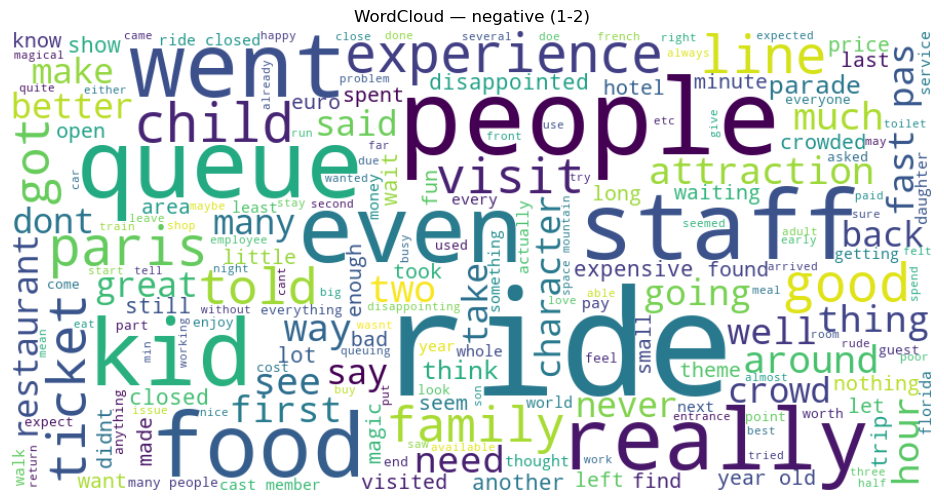

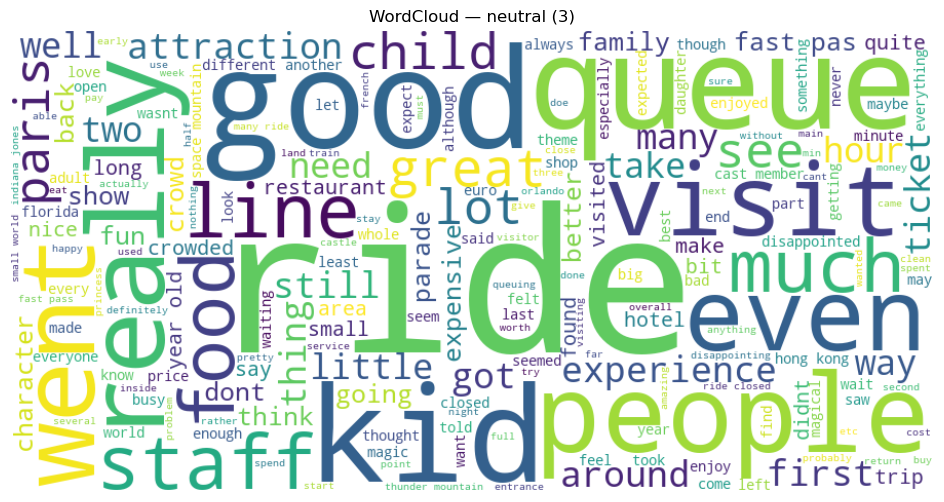

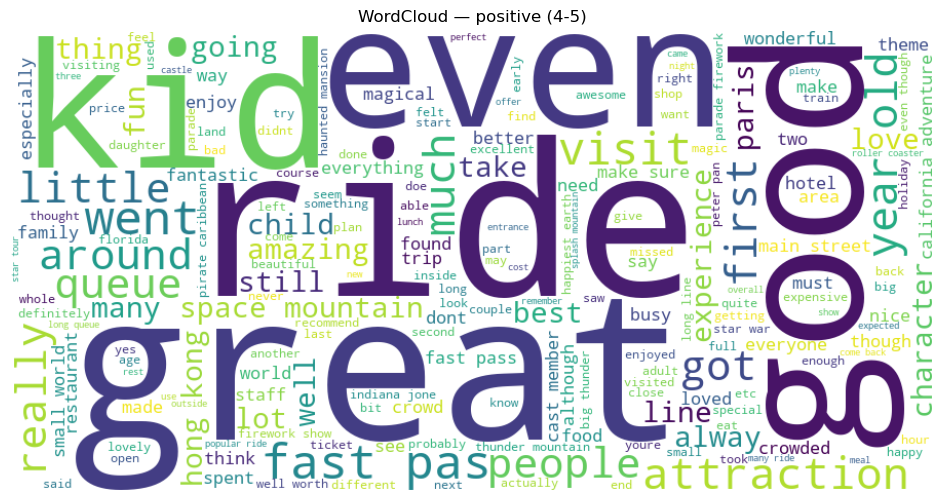

In [37]:
def make_wordcloud(tokens, title, extra_stopwords=None):
    if extra_stopwords is None:
        extra_stopwords = set()
    tokens = [t for t in tokens if t not in extra_stopwords and len(t) > 2]
    text = " ".join(tokens)
    
    wc = WordCloud(width=900, height=450, background_color="white").generate(text)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()

for cls in classes_order:
    subset = df[df["rating_bin"] == cls]
    tokens = [t for doc in subset["tokens_final"] for t in doc]
    make_wordcloud(tokens, title=f"WordCloud - {cls}", extra_stopwords=extra_wc_stopwords)


Across all three sentiment classes, the vocabulary overlaps strongly: words such as ride, queue/line, wait, people, ticket, time, staff, visit/experience appear in every cloud. This indicates that reviewers largely discuss the same core aspects of the visit, and sentiment is often expressed through adjectives and framing rather than completely different topics.

Negative (1–2): there is no single standout keyword; instead, the cloud is flatter, with many shared visit/logistics terms (e.g., wait/queue, crowded/people, staff, ticket, experience) appearing at similar sizes-suggesting negativity is expressed more through context/phrasing than unique “negative-only” topics.

Neutral (3): compared to positive/negative, neutral reviews are more dominated by descriptive/logistics vocabulary (e.g., queue/line, people, ticket, time) with fewer strong polarity words.

Positive (4–5): the most distinctive signal is the higher presence of explicitly positive words such as good, great, amazing, and family-oriented terms like kid/family.


### 3.5 TF - IDF

In [38]:
# Inputs
X_text = df["text_tfidf"].fillna("").astype(str)
y = df["rating_bin"]

# Train/test split (stratified)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TF-IDF Vectorizer 
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.85,
    sublinear_tf=True,
    stop_words=None  # IMPORTANT: stopwords already removed in tokens_final/text_tfidf
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF settings: ngram_range=(1,2), min_df=10, max_df=0.85")
print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf  shape:", X_test_tfidf.shape)


feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
mean_tfidf = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top_idx = np.argsort(mean_tfidf)[::-1][:20]

top_features_df = pd.DataFrame({
    "feature": feature_names[top_idx],
    "mean_tfidf": mean_tfidf[top_idx]
})

print("\nTop 20 features by mean TF-IDF (train):")
display(top_features_df)


TF-IDF settings: ngram_range=(1,2), min_df=10, max_df=0.85
X_train_tfidf shape: (29704, 28012)
X_test_tfidf  shape: (7426, 28012)

Top 20 features by mean TF-IDF (train):


,feature,mean_tfidf
0,ride,0.027576
1,time,0.024096
2,day,0.023720
3,not,0.022254
4,great,0.017786
5,place,0.017096
6,go,0.017026
7,get,0.016881
8,one,0.016419
9,kid,0.016016


We set min_df=10 to remove extremely rare terms and reduce noise (e.g., typos and highly idiosyncratic expressions), and max_df=0.85 to filter out overly common terms that carry little discriminatory information. This improves computational efficiency and interpretability while keeping sufficiently frequent, meaningful features for classification.

In [39]:
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
idf_values = tfidf_vectorizer.idf_

idf_df = pd.DataFrame({
    "feature": feature_names,
    "idf": idf_values
}).sort_values("idf", ascending=False).reset_index(drop=True)

print("Highest IDF (rarest features):")
display(idf_df.head(20))

print("Lowest IDF (most common features):")
display(idf_df.tail(20))


Highest IDF (rarest features):


,feature,idf
0,uniqueness,8.901175
1,closed indiana,8.901175
2,start firework,8.901175
3,week much,8.901175
4,overworked,8.901175
5,week may,8.901175
6,time car,8.901175
7,closed construction,8.901175
8,time castle,8.901175
9,week lot,8.901175


Lowest IDF (most common features):


,feature,idf
27992,really,2.626242
27993,show,2.612135
27994,much,2.610111
27995,like,2.608597
27996,line,2.586804
27997,parade,2.548388
27998,year,2.525067
27999,good,2.524294
28000,visit,2.519975
28001,food,2.431925


In [41]:
mean_tfidf = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top_idx = np.argsort(mean_tfidf)[::-1][:20]

global_top_df = pd.DataFrame({
    "feature": feature_names[top_idx],
    "mean_tfidf": mean_tfidf[top_idx]
})

print("Top 20 features by mean TF-IDF (train corpus):")
display(global_top_df)


Top 20 features by mean TF-IDF (train corpus):


,feature,mean_tfidf
0,ride,0.027576
1,time,0.024096
2,day,0.023720
3,not,0.022254
4,great,0.017786
5,place,0.017096
6,go,0.017026
7,get,0.016881
8,one,0.016419
9,kid,0.016016


The lowest IDF features are the terms that occur in a very large share of reviews, so they describe the common Disneyland review vocabulary rather than what differentiates documents. In our case, these are mostly generic visit-context words (ride, time, day, go, get, one, visit, place) and broadly used evaluation words (good, great, really, much, like), plus recurring operational themes such as queues (line) and typical attractions/events (parade).

Importantly, “not” appears among the most common features, which suggests that negation is widespread across the dataset (and therefore worth preserving for sentiment modelling). Overall, these low-IDF terms are expected: they capture what people talk about almost regardless of sentiment, which is exactly why TF–IDF later helps shift attention toward more specific, less universal terms.

In [42]:
print(df.isna().sum())

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
rating_bin           0
Year                 0
raw_length           0
tokens_tokenized     0
tokens_lemmatized    0
tokens_final         0
text_tfidf           0
dtype: int64


In [43]:
# Saving a "clean" dataset (for reproducibility)
cols_to_save = [
    "Review_ID", "Branch", "Rating", "rating_bin", "Year", "Year_Month",
    "Reviewer_Location", "Review_Text", "text_tfidf"
]

df_clean = df[cols_to_save].copy()

df_clean["tokens_final_str"] = df["tokens_final"].apply(lambda toks: " ".join(toks))

df_clean.to_csv("DisneylandReviews_preprocessed_clean.csv", index=False)
print("Saved CSV:", df_clean.shape)
print("File: DisneylandReviews_preprocessed_clean.csv")


Saved CSV: (37130, 10)
File: DisneylandReviews_preprocessed_clean.csv


Data set is prepared, saved and ready for further analysis

### 3.7 Topic modelling

In [44]:
X_text_full = df["text_tfidf"].fillna("").astype(str)

tfidf_tm = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.85,
    sublinear_tf=True
)

X_tfidf_full = tfidf_tm.fit_transform(X_text_full)
feature_names = np.array(tfidf_tm.get_feature_names_out())

k_topics = 6  
nmf = NMF(n_components=k_topics, random_state=42, init="nndsvda", max_iter=300)

W = nmf.fit_transform(X_tfidf_full)  
H = nmf.components_                  

def show_top_words(H, feature_names, top_n=12):
    topics = []
    for topic_idx, topic_weights in enumerate(H):
        top_idx = topic_weights.argsort()[::-1][:top_n]
        top_terms = feature_names[top_idx]
        topics.append((topic_idx, ", ".join(top_terms)))
    return pd.DataFrame(topics, columns=["topic_id", "top_terms"])

topics_df = show_top_words(H, feature_names, top_n=12)
print("NMF topics (top terms):")
display(topics_df)


NMF topics (top terms):


,topic_id,top_terms
0,0,"not, queue, food, one, good, no, people, get, ..."
1,1,"earth, place earth, happiest, happiest place, ..."
2,2,"fast, pas, line, fast pas, get, wait, ride, ti..."
3,3,"mountain, space, space mountain, ride, thunder..."
4,4,"hong, kong, hong kong, visit, day, small, smal..."
5,5,"great, time, year, kid, fun, amazing, love, lo..."


In [45]:
# Dominant topic per review
df["topic_id"] = W.argmax(axis=1)
df["topic_strength"] = W.max(axis=1)

topic_label = dict(zip(topics_df["topic_id"], topics_df["top_terms"]))
df["topic_terms"] = df["topic_id"].map(topic_label)

print("Sample reviews with assigned topics:")
display(df[["Rating", "rating_bin", "Branch", "topic_id", "topic_strength", "topic_terms", "text_tfidf"]].head(5))

# topic distribution by sentiment (counts) 
topic_by_sent = pd.crosstab(df["rating_bin"], df["topic_id"])
print("\nTopic counts by sentiment:")
display(topic_by_sent)

# topic distribution by location (counts)
topic_by_branch = pd.crosstab(df["Branch"], df["topic_id"])
print("\nTopic counts by branch:")
display(topic_by_branch)


print("\nMost representative reviews per topic (top 3 by strength):")
for t in range(k_topics):
    sub = df[df["topic_id"] == t].sort_values("topic_strength", ascending=False).head(3)
    print(f"\nTopic {t}: {topic_label[t]}")
    display(sub[["Rating", "rating_bin", "Branch", "topic_strength", "Review_Text"]])


Sample reviews with assigned topics:


,Rating,rating_bin,Branch,topic_id,topic_strength,topic_terms,text_tfidf
14,5,positive (4-5),Disneyland_HongKong,5,0.034444,"great, time, year, kid, fun, amazing, love, lo...",place huge definately need one day child aged ...
19,5,positive (4-5),Disneyland_HongKong,0,0.010866,"not, queue, food, one, good, no, people, get, ...",nothing say except become child step inside hk...
27,5,positive (4-5),Disneyland_HongKong,4,0.058586,"hong, kong, hong kong, visit, day, small, smal...",hong kong time already still want come back ri...
34,4,positive (4-5),Disneyland_HongKong,4,0.035543,"hong, kong, hong kong, visit, day, small, smal...",la two time tokyo sea walking gate hk felt lik...
38,5,positive (4-5),Disneyland_HongKong,5,0.016790,"great, time, year, kid, fun, amazing, love, lo...",visit understand memorable experience place br...



Topic counts by sentiment:


topic_id,0,1,2,3,4,5
rating_bin,,,,,,
negative (1-2),2002,102,410,210,103,158
neutral (3),2331,90,582,517,304,609
positive (4-5),6718,1225,4275,3228,1684,12582



Topic counts by branch:


...

,Rating,rating_bin,Branch,topic_strength,Review_Text
16493,5,positive (4-5),Disneyland_California,0.131857,"Make sure you do space mountain, big thunder, ..."
10931,5,positive (4-5),Disneyland_California,0.130220,Where adults can be kids. Must see: Matterhorn...
21915,5,positive (4-5),Disneyland_California,0.128061,The corndogs are the best!! The rides like Big...



Topic 4: hong, kong, hong kong, visit, day, small, smaller, hk, one, mtr, must, attraction


,Rating,rating_bin,Branch,topic_strength,Review_Text
8132,3,neutral (3),Disneyland_HongKong,0.143512,Hong Kong Disneyland is complete family Entert...
3545,5,positive (4-5),Disneyland_HongKong,0.138592,We spent the whole day in Hong Kong Disneyland...
3960,5,positive (4-5),Disneyland_HongKong,0.132925,We have been to Disneyland in Hong Kong 4 time...



Topic 5: great, time, year, kid, fun, amazing, love, loved, parade, old, family, day


,Rating,rating_bin,Branch,topic_strength,Review_Text
36630,5,positive (4-5),Disneyland_Paris,0.072575,most magical place for kids and adult alike de...
35287,5,positive (4-5),Disneyland_Paris,0.071850,I actually don't know where to start!! Me and ...
17529,5,positive (4-5),Disneyland_California,0.071413,We are not the family that visits Disney regul...


The NMF model identifies six recurring themes that capture what visitors most often discuss, largely independent of rating:

**Topic 0** (operations & complaints/mixed service): this looks like a “friction” topic combining practical issues (lines, crowds, food) and evaluative language.

**Topic 1** (iconic slogan / overall praise): strongly positive framing-mostly associated with 5-star reviews and classic “Disney magic” statements.

**Topic 2** (waiting-time management / FastPass): time-focused on how visitors navigate queues and planning; relevant across ratings because it is a core part of the park experience.

**Topic 3** (attractions / ride names): ride-centric content typical for recommendation-style reviews.

**Topic 4** (Hong Kong-specific context): clearly location-linked.

**Topic 5** (family enjoyment & “great time”): experience-driven positivity.


Two patterns are especially informative. First, the topic distributions show that positive reviews dominate overall, but importantly they are not “one topic”: high ratings spread across family enjoyment (Topic 5), iconic praise (Topic 1), rides (Topic 3), and queue management (Topic 2). Second, topics differ across locations: Hong Kong reviews concentrate strongly in Topic 4, while California shows more attraction-focused Topic 3 and FastPass Topic 2, and Paris has a large share of Topic 0, suggesting that operational/service and practical issues appear more frequently in Paris reviews in this dataset.
Overall, this segment helps move beyond a simple “good vs bad” sentiment view by showing what people talk about when they rate: logistics and queues, attraction highlights, family experience, and location-specific characteristics.

## 4. Sentiment analysis methods

###  4.1 Dictionary based - VADER

In [47]:
# using already cleaned data set
df_clean = pd.read_csv("DisneylandReviews_preprocessed_clean.csv")
print(df_clean.shape)
df_clean[["Rating", "rating_bin", "Branch", "Review_Text", "text_tfidf"]].head()


(37130, 10)


,Rating,rating_bin,Branch,Review_Text,text_tfidf
0,5,positive (4-5),Disneyland_HongKong,This place is HUGE! Definately need more than ...,place huge definately need one day child aged ...
1,5,positive (4-5),Disneyland_HongKong,There is nothing more to say except that you b...,nothing say except become child step inside hk...
2,5,positive (4-5),Disneyland_HongKong,We have been to Hong Kong Disneyland a few tim...,hong kong time already still want come back ri...
3,4,positive (4-5),Disneyland_HongKong,"We have been to Disneyland in LA two times, an...",la two time tokyo sea walking gate hk felt lik...
4,5,positive (4-5),Disneyland_HongKong,You have to visit to understand the memorable ...,visit understand memorable experience place br...


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\48661\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


VADER accuracy: 0.7943
VADER F1 (weighted): 0.7556

Classification report:
                precision    recall  f1-score   support

negative (1-2)       0.37      0.45      0.41      2985
   neutral (3)       0.21      0.03      0.05      4433
positive (4-5)       0.85      0.94      0.90     29712

      accuracy                           0.79     37130
     macro avg       0.48      0.48      0.45     37130
  weighted avg       0.74      0.79      0.76     37130



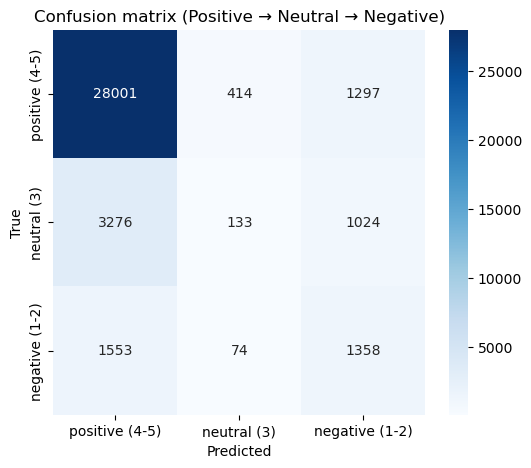

In [48]:
sia = SentimentIntensityAnalyzer()

# VADER score 
df_clean["vader_compound"] = df_clean["Review_Text"].fillna("").apply(
    lambda x: sia.polarity_scores(x)["compound"]
)

def vader_label(score, thr=0.05):
    if score >= thr:
        return "positive (4-5)"
    elif score <= -thr:
        return "negative (1-2)"
    else:
        return "neutral (3)"

df_clean["vader_sentiment"] = df_clean["vader_compound"].apply(lambda s: vader_label(s, thr=0.05))

# Metrics
y_true = df_clean["rating_bin"]
y_pred = df_clean["vader_sentiment"]

acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average="weighted")

print("VADER accuracy:", round(acc, 4))
print("VADER F1 (weighted):", round(f1, 4))

print("\nClassification report:")
print(classification_report(y_true, y_pred))

# Confusion matrix
labels_order = ["positive (4-5)", "neutral (3)", "negative (1-2)"] # same for all models

cm = confusion_matrix(y_true, y_pred, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix (Positive → Neutral → Negative)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In our dataset, VADER achieves **accuracy = 0.7943** and **weighted F1 = 0.7556**, which is driven mainly by the dominant positive (4–5) class. The confusion matrix and classification report show that VADER performs strongly for positive reviews (precision 0.85, recall 0.94), meaning it usually recognizes clearly enthusiastic language well. However, it **struggles substantially with the neutral class** (precision 0.21, recall 0.03, F1 0.05): most truly neutral (3-star) reviews are pushed into positive (and to a lesser extent negative), which is consistent with the idea that many “neutral” tourism reviews still contain mixed but generally positive wording.

The method also has limited ability to separate subtle dissatisfaction from genuinely negative sentiment, because it does not learn domain context (e.g., “long queue but worth it” contains both negative and positive cues). Overall, VADER is still useful as a baseline dictionary approach, but the weak neutral detection makes the performance not fully satisfactory for our research goals-therefore, we proceed with supervised machine-learning models, which can learn domain-specific patterns and better handle nuanced or mixed reviews.

In [49]:
sia = SentimentIntensityAnalyzer()
if "vader_compound" not in df_clean.columns:
    df_clean["vader_compound"] = df_clean["Review_Text"].fillna("").apply(
        lambda x: sia.polarity_scores(x)["compound"]
    )

#  Label function 
def vader_label(score, thr):
    if score >= thr:
        return "positive (4-5)"
    elif score <= -thr:
        return "negative (1-2)"
    else:
        return "neutral (3)"

# Compare thresholds 
thresholds = [0.05, 0.10] 
labels_order = ["negative (1-2)", "neutral (3)", "positive (4-5)"]

y_true = df_clean["rating_bin"]

comparison_rows = []

for thr in thresholds:
    pred_col = f"vader_sentiment_thr_{thr}"
    df_clean[pred_col] = df_clean["vader_compound"].apply(lambda s: vader_label(s, thr))

    y_pred = df_clean[pred_col]

    acc = accuracy_score(y_true, y_pred)
    f1w = f1_score(y_true, y_pred, average="weighted")

    print(f"\nThreshold ±{thr}")
    print(classification_report(y_true, y_pred, labels=labels_order))

    rep = classification_report(
        y_true, y_pred,
        labels=labels_order,
        output_dict=True,
        zero_division=0
    )
    rep_df = pd.DataFrame(rep).T.reset_index().rename(columns={"index": "label"})
    rep_df["threshold"] = f"±{thr}"

    rep_df = rep_df[rep_df["label"].isin(labels_order + ["accuracy"])].copy()
    rep_df["accuracy_overall"] = acc
    rep_df["f1_weighted_overall"] = f1w

    comparison_rows.append(rep_df)

# Final comparison table 
comparison_df = pd.concat(comparison_rows, ignore_index=True)

comparison_df["label"] = pd.Categorical(comparison_df["label"], categories=labels_order + ["accuracy"], ordered=True)
comparison_df = comparison_df.sort_values(["threshold", "label"])

display(comparison_df[[
    "threshold", "label", "precision", "recall", "f1-score", "support",
    "accuracy_overall", "f1_weighted_overall"
]])


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\48661\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!



Threshold ±0.05
                precision    recall  f1-score   support

negative (1-2)       0.37      0.45      0.41      2985
   neutral (3)       0.21      0.03      0.05      4433
positive (4-5)       0.85      0.94      0.90     29712

      accuracy                           0.79     37130
     macro avg       0.48      0.48      0.45     37130
  weighted avg       0.74      0.79      0.76     37130


Threshold ±0.1
                precision    recall  f1-score   support

negative (1-2)       0.37      0.44      0.41      2985
   neutral (3)       0.23      0.04      0.07      4433
positive (4-5)       0.85      0.94      0.89     29712

      accuracy                           0.79     37130
     macro avg       0.48      0.48      0.46     37130
  weighted avg       0.74      0.79      0.76     37130



,threshold,label,precision,recall,f1-score,support,accuracy_overall,f1_weighted_overall
0,±0.05,negative (1-2),0.369122,0.454941,0.407563,2985.00000,0.79429,0.755586
1,±0.05,neutral (3),0.214171,0.030002,0.052632,4433.00000,0.79429,0.755586
2,±0.05,positive (4-5),0.852909,0.942414,0.895430,29712.00000,0.79429,0.755586
3,±0.05,accuracy,0.794290,0.794290,0.794290,0.79429,0.79429,0.755586
4,±0.1,negative (1-2),0.372093,0.444891,0.405249,2985.00000,0.79289,0.757514
5,±0.1,neutral (3),0.226136,0.044891,0.074911,4433.00000,0.79289,0.757514
6,±0.1,positive (4-5),0.854105,0.939452,0.894748,29712.00000,0.79289,0.757514
7,±0.1,accuracy,0.792890,0.792890,0.792890,0.79289,0.79289,0.757514


Threshold tuning does not meaningfully improve neutral sentiment detection in VADER. For the final output we stayed with 0.05 treshold. 


In [80]:
results = []

def add_result(model_name, accuracy, f1_weighted):
    results.append({
        "model": model_name,
        "accuracy": float(accuracy),
        "f1_weighted": float(f1_weighted)
    })

def show_results(sort_by="accuracy", ascending=False):
    df_res = pd.DataFrame(results)
    if len(df_res) == 0:
        print("No results yet.")
        return df_res
    df_res = df_res.sort_values(sort_by, ascending=ascending).reset_index(drop=True)
    display (df_res)
    return df_res

In [51]:
add_result("VADER", acc, f1w)


### 4.2 MACHINE LEARNING MODELS 

### 4.2.1 Naive Bayes

Best alpha: 0.1
Best CV accuracy: 0.843
Test accuracy: 0.8459
Test F1 (weighted): 0.8117


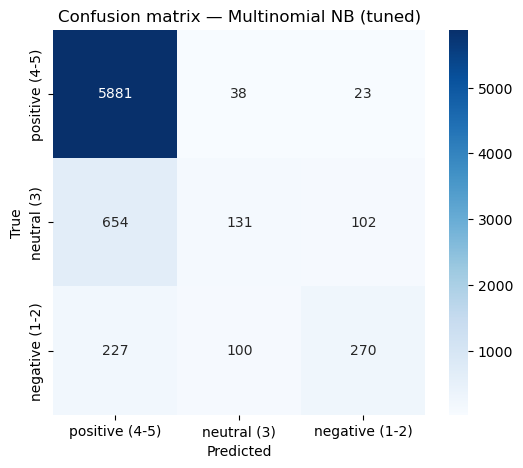

In [54]:
# 1. Model
nb = MultinomialNB()

# 2. Hyperparameters to tune
param_grid = {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0]}

# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search 
grid_nb = GridSearchCV(
    estimator=nb,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# 5. Fitting model and evaluating on test set
grid_nb.fit(X_train_tfidf, y_train)

print("Best alpha:", grid_nb.best_params_["alpha"])
print("Best CV accuracy:", np.round(grid_nb.best_score_, 4))

best_nb = grid_nb.best_estimator_
y_pred_nb = best_nb.predict(X_test_tfidf)

acc_nb = accuracy_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb, average="weighted")

print("Test accuracy:", np.round(acc_nb, 4))
print("Test F1 (weighted):", np.round(f1_nb, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - Multinomial NB (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table 
add_result("Multinomial NB (tuned)", acc_nb, f1_nb)


For Multinomial Naive Bayes, we performed hyperparameter tuning (smoothing parameter 𝛼) with stratified cross-validation, selecting **𝛼=0.1** as the best setting. The tuned model achieves **accuracy = 0.8459** and **weighted F1 = 0.8117**, showing a clear improvement over lexicon-based methods and generally strong performance for the dominant positive class, while neutral reviews remain the most challenging and are still frequently predicted as positive.

### 4.2.2 Logistic Regression

Best params: {'C': 10, 'penalty': 'l2'}
Best CV accuracy: 0.8481
Test accuracy: 0.8501
Test F1 (weighted): 0.8373


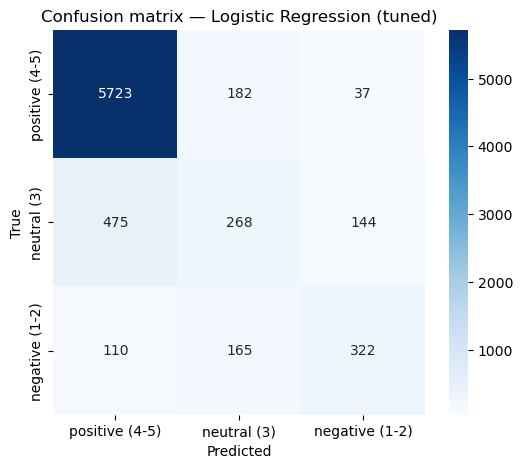

In [56]:
# 1. Model
lr = LogisticRegression(
    random_state=42,
    max_iter=5000,
    multi_class="multinomial",
    solver="saga")

# 2. Hyperparameters to tune
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l2"]}

# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search
grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

 # 5. Fitting model and evaluating on test set
grid_lr.fit(X_train_tfidf, y_train)

print("Best params:", grid_lr.best_params_)
print("Best CV accuracy:", np.round(grid_lr.best_score_, 4))

best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_tfidf)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="weighted")

print("Test accuracy:", np.round(acc_lr, 4))
print("Test F1 (weighted):", np.round(f1_lr, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - Logistic Regression (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table
add_result("Logistic Regression (tuned)", acc_lr, f1_lr)


For the tuned Logistic Regression model, the best configuration was **C=10 with an L2 penalty**, and it achieves **accuracy = 0.8501** with **weighted F1 = 0.8373**. Compared with Multinomial NB, this is a small but consistent improvement (higher accuracy and noticeably higher F1). From the confusion matrix, Logistic Regression still performs strongest on positive (4–5) reviews (most cases correctly classified), but it handles the neutral (3) category better than NB (more neutrals correctly identified and fewer collapsed into “positive”).

### 4.2.3  K-Nearest Neighbor

Best params: {'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
Best CV accuracy: 0.8003
Test accuracy: 0.8002
Test F1 (weighted): 0.7113


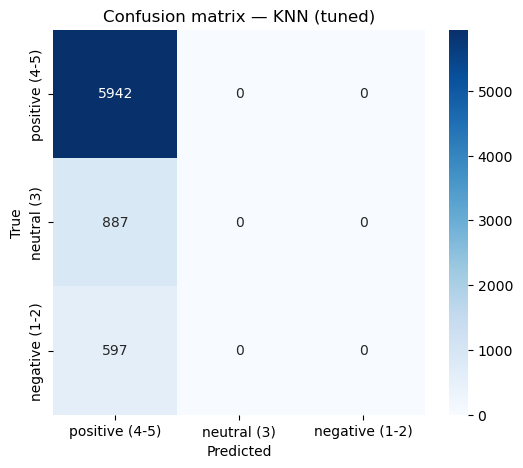

In [58]:
# 1. Model
knn = KNeighborsClassifier()

# 2. Hyperparameter grid
param_grid = {
    "n_neighbors": [2,3,4,7,9],
    "weights": ["distance", "uniform"],
    "p": [1,2]  # 1 = Manhattan 2= Euclidean 
}

# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search
grid_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

# 5. Fitting model and evaluating on test set
grid_knn.fit(X_train_tfidf, y_train)

print("Best params:", grid_knn.best_params_)
print("Best CV accuracy:", np.round(grid_knn.best_score_, 4))

best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test_tfidf)

acc_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn, average="weighted")

print("Test accuracy:", np.round(acc_knn, 4))
print("Test F1 (weighted):", np.round(f1_knn, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - KNN (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table 
add_result("KNN (tuned)", acc_knn, f1_knn)


For KNN (tuned) we tested multiple hyperparameter settings (different k, distance metrics, and weighting schemes), but the model still collapses to a single-class prediction: virtually everything is classified as “positive (4–5)”. This is visible directly in the confusion matrix (only the first prediction column is populated), and it explains the weak overall performance: **accuracy = 0.8002** and **weighted F1 = 0.7113**, which is mainly driven by the dominance of the positive class in the dataset rather than meaningful discrimination.

A likely reason KNN struggles here is that TF–IDF feature space is high-dimensional and sparse, making distance-based “nearest neighbour” similarity unreliable (many documents look similarly distant from each other, so neighbourhoods are not informative). In addition, the dataset is strongly imbalanced toward positive reviews, so local neighbourhoods are often dominated by positive examples-leading KNN to default to the majority class even after tuning.

### 4.2.4 Support Vector Classifier

Best params: {'C': 1}
Best CV accuracy: 0.8474
Test accuracy: 0.8507
Test F1 (weighted): 0.8338


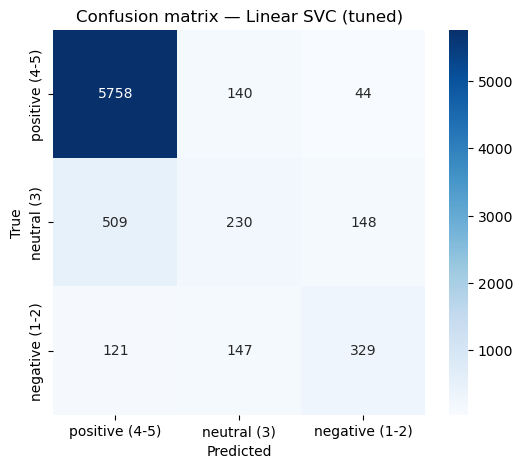

In [60]:
# 1. Model
svc = LinearSVC(random_state=42)

# 2. Hyperparameter grid
param_grid = {"C": [0.01, 0.1, 1, 10]}

# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search 
grid_svc = GridSearchCV(
    estimator=svc,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

# 5. Fitting model and evaluating on test set
grid_svc.fit(X_train_tfidf, y_train)

print("Best params:", grid_svc.best_params_)
print("Best CV accuracy:", np.round(grid_svc.best_score_, 4))

best_svc = grid_svc.best_estimator_
y_pred_svc = best_svc.predict(X_test_tfidf)

acc_svc = accuracy_score(y_test, y_pred_svc)
f1_svc = f1_score(y_test, y_pred_svc, average="weighted")

print("Test accuracy:", np.round(acc_svc, 4))
print("Test F1 (weighted):", np.round(f1_svc, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_svc = confusion_matrix(y_test, y_pred_svc, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_svc, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - Linear SVC (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table 
add_result("Linear SVC (tuned)", acc_svc, f1_svc)


Linear SVC achieves test **accuracy = 0.8507** and **weighted F1** = 0.8338, so it performs very well and is among the top classical ML models in this project. It predicts the positive (4–5) class reliably, but it struggles most with the neutral (3) class, which is often confused with positive. The negative (1–2) class is detected better than in VADER, although some negative reviews are still misclassified.

### 4.2.5 Random Forest

Best params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV accuracy: 0.8006
Test accuracy: 0.8006
Test F1 (weighted): 0.7124


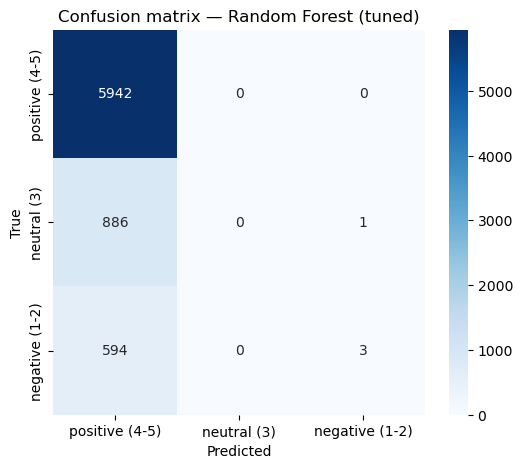

In [63]:
# 1. Model
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1)

# 2. Hyperparameter grid
param_grid = {
    "n_estimators": [200],
    "max_depth": [None, 5],
    "min_samples_split": [2,5],
    "min_samples_leaf": [2]}

# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search 
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

# 5. Fitting model and evaluating on test set
grid_rf.fit(X_train_tfidf, y_train)

print("Best params:", grid_rf.best_params_)
print("Best CV accuracy:", np.round(grid_rf.best_score_, 4))

best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_tfidf)

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="weighted")

print("Test accuracy:", np.round(acc_rf, 4))
print("Test F1 (weighted):", np.round(f1_rf, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - Random Forest (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table 
add_result("Random Forest (tuned)", acc_rf, f1_rf)


Random Forest reaches test **accuracy = 0.8006** and **weighted F1 = 0.7124**, which is clearly weaker than the linear models in this project. Hyperparameter tuning was intentionally limited to a small grid for runtime reasons (with fixed settings such as the number of trees and a constrained min_samples_leaf), but the confusion matrix suggests the issue is not just “a slightly wrong grid” - the model largely collapses to predicting the majority class (positive). This behavior is common for RF on high-dimensional sparse TF-IDF features, where trees struggle to find stable split rules and tend to overfit noise while still being biased toward the dominant class. In contrast, linear models (LR / Linear SVC) are typically better suited to sparse text data because they learn global linear decision boundaries that generalize well in this feature space.

### 4.2.6 XGBoost

XGB classes: ['negative (1-2)', 'neutral (3)', 'positive (4-5)']
Best params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 400}
Best CV accuracy: 0.8418
Test accuracy: 0.8449
Test F1 (weighted): 0.8158


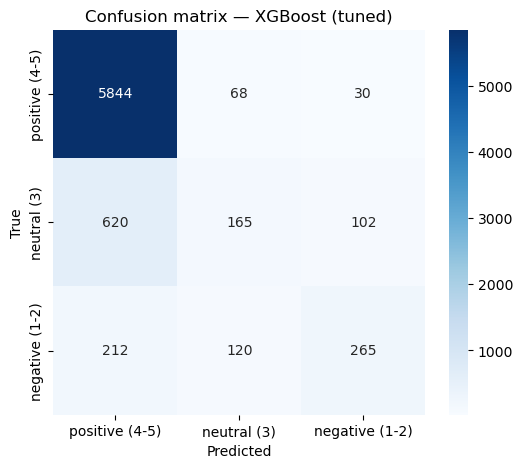

In [65]:
# 0. Label encode y 
label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb  = label_encoder.transform(y_test)

print("XGB classes:", list(label_encoder.classes_))

# 1. Model
xgb = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    subsample=0.8,
    colsample_bytree=0.8)

# 2. Hyperparameter grid 
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.1]}


# 3. Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Grid search 
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

# 5. Fitting model and evaluating on test set
grid_xgb.fit(X_train_tfidf, y_train_xgb)

print("Best params:", grid_xgb.best_params_)
print("Best CV accuracy:", np.round(grid_xgb.best_score_, 4))

best_xgb = grid_xgb.best_estimator_

y_pred_xgb_num = best_xgb.predict(X_test_tfidf)
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_num)  

acc_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb, average="weighted")

print("Test accuracy:", np.round(acc_xgb, 4))
print("Test F1 (weighted):", np.round(f1_xgb, 4))

# 6. Confusion matrix (Positive → Neutral → Negative)
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion matrix - XGBoost (tuned)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 7. Add to results table 
add_result("XGBoost (tuned)", acc_xgb, f1_xgb)


XGBoost (tuned) achieves test **accuracy = 0.8449** and **weighted F1 = 0.8158**. For efficiency and stability, part of the configuration was fixed in advance (subsample=0.8 and colsample_bytree=0.8), while the search focused on the most influential knobs (n_estimators, max_depth, learning_rate). The confusion matrix shows that the model performs very well on the dominant positive class, but still struggles to reliably separate the minority classes - many neutral reviews are pulled into “positive”, and negatives are only partially recovered. Overall, this is a solid supervised baseline, but it does not clearly outperform the best linear model in a way that would justify its higher complexity, so the next step is to test a stronger transformer-based approach to see whether contextual embeddings can improve performance, especially for borderline/neutral cases.

### 4.3 Transformed base method - BERT

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Processed 16/37130 texts...
Processed 976/37130 texts...
Processed 1936/37130 texts...
Processed 2896/37130 texts...
Processed 3856/37130 texts...
Processed 4816/37130 texts...
Processed 5776/37130 texts...
Processed 6736/37130 texts...
Processed 7696/37130 texts...
Processed 8656/37130 texts...
Processed 9616/37130 texts...
Processed 10576/37130 texts...
Processed 11536/37130 texts...
Processed 12496/37130 texts...
Processed 13456/37130 texts...
Processed 14416/37130 texts...
Processed 15376/37130 texts...
Processed 16336/37130 texts...
Processed 17296/37130 texts...
Processed 18256/37130 texts...
Processed 19216/37130 texts...
Processed 20176/37130 texts...
Processed 21136/37130 texts...
Processed 22096/37130 texts...
Processed 23056/37130 texts...
Processed 24016/37130 texts...
Processed 24976/37130 texts...
Processed 25936/37130 texts...
Processed 26896/37130 texts...
Processed 27856/37130 texts...
Processed 28816/37130 texts...
Processed 29776/37130 texts...
Processed 30736/37130 

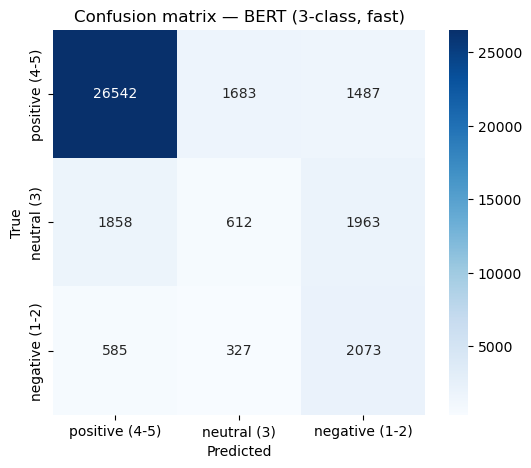

In [70]:
# 1) 3-class sentiment pipeline (positive / neutral / negative)
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

sent_pipe = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=-1)

# 2) Prepare texts:
texts = (
    df_clean["Review_Text"]
    .fillna("")
    .astype(str)
    .str.slice(0, 300)
    .tolist()
)

# label mapping
map_to_project = {
    "positive": "positive (4-5)",
    "neutral": "neutral (3)",
    "negative": "negative (1-2)"
}

# 3) Batch prediction
BATCH_SIZE = 16  
MAX_LEN = 128     

all_preds = []
n = len(texts)

for start in range(0, n, BATCH_SIZE):
    end = min(start + BATCH_SIZE, n)
    batch_texts = texts[start:end]

    batch_out = sent_pipe(
        batch_texts,
        truncation=True,
        max_length=MAX_LEN
    )

    all_preds.extend(batch_out)

    # progress every ~1000 texts
    if start % (BATCH_SIZE * 60) == 0:
        print(f"Processed {end}/{n} texts...")

df_clean = df_clean.copy()
df_clean["bert_label"] = [map_to_project[p["label"].lower()] for p in all_preds]
df_clean["bert_score"] = [p["score"] for p in all_preds]

# 4) Evaluate
y_true = df_clean["rating_bin"].astype(str)
y_pred = df_clean["bert_label"].astype(str)

acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average="weighted")

print("\nBERT 3-class (fast) accuracy:", np.round(acc, 4))
print("BERT 3-class (fast) F1 weighted:", np.round(f1, 4))
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, digits=4))

# Confusion matrix order: Positive -> Neutral -> Negative 
cm = confusion_matrix(y_true, y_pred, labels=labels_order)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels_order, yticklabels=labels_order
)
plt.title("Confusion matrix - BERT (3-class, fast)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 5) Save result 
add_result("BERT", acc, f1)


To keep the Transformer inference computationally feasible on a large corpus of long reviews, we truncated the input text (first 300 characters) and limited tokenization to max_length=128. This preserves the main sentiment signal while substantially reducing runtime.

BERT reaches **accuracy = 0.7872** and **weighted F1 = 0.7836**. Compared to the dictionary-based approach (VADER), it is broadly competitive: the overall performance is similar in accuracy, with slightly better balance in F1, but it still struggles with the neutral class (very low neutral recall, with many neutral reviews absorbed into the positive class).
Against the supervised models, this BERT variant does not win: Logistic Regression / Linear SVC achieve around ~0.85 accuracy and ~0.83–0.84 weighted F1, so they clearly outperform BERT on this dataset.

In [71]:
show_results()

,model,accuracy,f1_weighted
0,Linear SVC (tuned),0.850660,0.833787
1,Logistic Regression (tuned),0.850121,0.837336
2,Multinomial NB (tuned),0.845947,0.811664
3,XGBoost (tuned),0.844869,0.815840
4,Random Forest (tuned),0.800566,0.712350
5,KNN (tuned),0.800162,0.711335
6,VADER,0.792890,0.757514
7,"BERT (3-class, fast)",0.787153,0.783583


,model,accuracy,f1_weighted
0,Linear SVC (tuned),0.850660,0.833787
1,Logistic Regression (tuned),0.850121,0.837336
2,Multinomial NB (tuned),0.845947,0.811664
3,XGBoost (tuned),0.844869,0.815840
4,Random Forest (tuned),0.800566,0.712350
5,KNN (tuned),0.800162,0.711335
6,VADER,0.792890,0.757514
7,"BERT (3-class, fast)",0.787153,0.783583


## 5. Results
### The best model - Logistic Regression

Logistic Regression achieved the best overall balance across classes, which is why it is used as the main supervised reference model in the project.
The model’s weighted F1 score is slightly higher than LinearSVC, suggesting that Logistic Regression is marginally better at balancing precision and recall across the three sentiment classes (positive / neutral / negative), rather than optimizing performance mostly on the dominant class (positive).
Because the dataset is imbalanced (many more positive reviews than neutral and negative), we prioritize weighted F1 alongside accuracy. This helps ensure that performance on minority classes is not hidden behind a high accuracy driven mainly by the majority class.

#### Ranking by F1 (weighted)

|   | Model | F1 (weighted) | Accuracy |
|---:|---|---:|---:|
| 1 | Logistic Regression (tuned) | 0.837336 | 0.850121 |
| 2 | Linear SVC (tuned) | 0.833787 | 0.850660 |
| 3 | XGBoost (tuned) | 0.815840 | 0.844869 |
| 4 | Multinomial NB (tuned) | 0.811664 | 0.845947 |
| 5 | BERT  | 0.783583 | 0.787153 |
| 6 | VADER | 0.757514 | 0.792890 |
| 7 | Random Forest (tuned) | 0.712350 | 0.800566 |
| 8 | KNN (tuned) | 0.711335 | 0.800162 |


 **Note on comparability:** The supervised TF-IDF models are evaluated on a held-out test split, while the dictionary-based (VADER) and transformer-based (BERT) methods are evaluated on a slightly different input scope in this notebook. We include them side-by-side primarily as a *practical benchmark* to compare families of approaches and identify the strongest overall method. The rankings should therefore be interpreted as indicative rather than a perfectly controlled head-to-head experiment.


#### Ranking by Accuracy

|   | Model | Accuracy | F1 (weighted) |
|---:|---|---:|---:|
| 1 | Linear SVC (tuned) | 0.850660 | 0.833787 |
| 2 | Logistic Regression (tuned) | 0.850121 | 0.837336 |
| 3 | Multinomial NB (tuned) | 0.845947 | 0.811664 |
| 4 | XGBoost (tuned) | 0.844869 | 0.815840 |
| 5 | Random Forest (tuned) | 0.800566 | 0.712350 |
| 6 | KNN (tuned) | 0.800162 | 0.711335 |
| 7 | VADER | 0.792890 | 0.757514 |
| 8 | BERT| 0.787153 | 0.783583 |


Among the remaining supervised models, LinearSVC is the closest competitor (very similar accuracy and F1), while MultinomialNB and XGBoost achieve solid but slightly weaker results. In contrast, KNN and Random Forest perform poorly in this setup, which is consistent with their limitations on sparse, high-dimensional TF-IDF text features.

The dictionary-based baseline (VADER) is useful as an interpretable reference point, but it struggles to capture mixed/neutral reviews and context-dependent language, so it is not strong enough as a final solution. The transformer-based model (BERT) provides a modern pretrained benchmark, yet it still does not surpass the best supervised TF-IDF models on this dataset without domain-specific fine-tuning.

Final decision: Logistic Regression is chosen as the main model because it provides the best overall balance (weighted F1) while keeping accuracy at the top level.

## Interpretation based on Logistic Regression

## RQ1 - How does sentiment relate to the rating (1–5 stars)?
Sentiment is strongly aligned with rating overall: most 4–5 star reviews are classified as positive and most 1–2 star reviews as negative. However, the relationship is not perfectly one-to-one: some reviews contain mixed signals ( high rating but complaints about queues or crowding). This motivates an error analysis: misaligned cases reveal non-trivial patterns such as “overall satisfaction despite specific pain points” or “strong emotions expressed in a narrative that ends with a high/low rating”.

## 6. Error analysis

 Error analysis dataset (test only)

In [91]:
# to dispaly full text of reviews
pd.set_option("display.max_colwidth", None)   
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 0)            

In [92]:
# df_test came from the SAME dataframe used in train_test_split (here: df)
df_test = df.loc[y_test.index].copy()

df_test["y_true"] = y_test
df_test["y_pred_lr"] = y_pred_lr
df_test["correct"] = (df_test["y_true"] == df_test["y_pred_lr"])

df_test[["Branch", "Rating", "y_true", "y_pred_lr", "correct", "Review_Text"]].head(3)



,Branch,Rating,y_true,y_pred_lr,correct,Review_Text
26577,Disneyland_California,5,positive (4-5),positive (4-5),True,"with all the new additions to California Adventure and the upgrades at Disneyland, it is a great time to check out the parks!"
30389,Disneyland_Paris,5,positive (4-5),positive (4-5),True,"I last visited Euro Disney in 1995, so it was great to be back last June. There's just something about Disney, it is magical.There is so much to do here! The famous cup saucer ride, It's a Small World, Haunted House, Indiana Jones roller coaster, Space Mountain, which is now remodelled to a Star Wars theme, the beautiful castle, Aladin's Agrabah, Robinson Crusoe's house, ... There are many shows too, so keep an eye out for them. It starts with a Disney one introducing all characters, then a dance of all the Disney princes and princesses. There is the evening parade that goes through Main Street and then finally the spectacular fireworks. The firerowkrs start really late, like 23:00 hrs but are totally worth it, so get some food and a seat and then don't move :PIt's Disney, so you have to load up on merchandise! They have some beautiful products and souvenirs. When we visited in 2017, it was the 25th anniversary of Disney in Paris, so the whole park had a 25th anniversary theme, and decorated in silver and blue. You can buy products and ask them to keep them to collect later or have them delivered to the main Disney store in Disney Village.There are many restaurants and some have some veg options, like fries and salads. We liked the fries at Hakuna Matata restaurant. Casey's Corner was also a nice diner, an had a Coca Cola theme going on. There are also many food trucks selling popcorn, pommel d'amour caramel apples , ice creams, and other drinks.We got a one day 2 park pass, although I'd recommend you to get just one day one park, because it takes a lot of time going from one park to another, and you can't do any properly. The queues get crazy long in the summers and around holidays, so it is better to book in advance.The staff is incredibly friendly and everyone speaks French and English, and many other languages too. There are toilets everywhere.The closest RER station is Marne la Vall e Chessy Parc Disneyland on RER A.Once again, it's Disney! Despite how commercial it is, I just love it!"
19172,Disneyland_California,5,positive (4-5),positive (4-5),True,This was my first trip to Disneyland & California Adventure. I have made many trips to Disney World. It was fun because everything was different enough to make it all very exciting. We went with my fianc 's family. His mother usually has a hard time keeping up with us so we rented her a scooter. I would recommend this to anyone who has this problem. She was comfortable and able to keep up with us all day long.


### 6.1 Error cases: 5★ → predicted negative

In [97]:
# 5 stars but predicted NEGATIVE by Logistic Regression
subset_5_neg = df_test[
    (df_test["Rating"] == 5) &
    (df_test["y_pred_lr"] == "negative (1-2)")
].head(5)

print("Found cases:", len(subset_5_neg))

for j, (_, row) in enumerate(subset_5_neg.iterrows(), 1):
    print("\n" + "="*100)
    header = f"CASE {j} | Branch: {row.get('Branch','')} | Rating: {row.get('Rating','')} | True: {row.get('y_true','')} | Pred(LR): {row.get('y_pred_lr','')}"
    print(header)

    print("-"*100)
    print(row.get("Review_Text",""))


Found cases: 5

CASE 1 | Branch: Disneyland_Paris | Rating: 5 | True: positive (4-5) | Pred(LR): negative (1-2)
----------------------------------------------------------------------------------------------------
Magical to say the least. Five stars but only because I couldn   t give the smaller brother next door eight out of five.Utterly enchanting and exceptionally value for money in my opinion. Mid August but queues were as expected. Not to that long to be fair. The fireworks and light show were the be all to end all. We went the last night as we didn   t need to return for magic time the following morning and I can honestly say that I have never been so mesmerised by a display.I   m struggling to find superlatives for this place so can only imagine what   s going through my daughter   s thoughts.Went to Florida many years before but don   t feel the need with this fascinating venue just over the channel.I can guarantee that    WE WILL BE RETURNING   !!!

CASE 2 | Branch: Disneyland

In the misclassified 5-star cases predicted as negative, the model is typically influenced by the presence of locally negative cues embedded within an otherwise positive narrative. Because Logistic Regression relies on TF-IDF features, strongly polarised tokens related to conflict, inconvenience, cost, or dissatisfaction can dominate the representation even when the overall conclusion is appreciative. This is especially common in reviews that follow a “positive, but…” structure, contain contrastive framing (e.g., expectations of something “worst” followed by “but”), or include detailed complaints about specific incidents (e.g., safety, rude behaviour, crowd management).

Typical phrases that can mislead the classifier include expressions such as “rude people”, “security … did nothing”, or “threats … in front of my children”-all of which carry a strong negative lexical signal despite the final rating being highly positive.

### 6.2 Error cases: 1★ → predicted positive

In [98]:
# 1 star but predicted POSITIVE by Logistic Regression
subset_1_pos = df_test[
    (df_test["Rating"] == 1) &
    (df_test["y_pred_lr"] == "positive (4-5)")
].head(5)

print("Found cases:", len(subset_1_pos))

for j, (_, row) in enumerate(subset_1_pos.iterrows(), 1):
    print("\n" + "="*100)
    header = f"CASE {j} | Branch: {row.get('Branch','')} | Rating: {row.get('Rating','')} | True: {row.get('y_true','')} | Pred(LR): {row.get('y_pred_lr','')}"
    print(header)
    print("-"*100)
    print(row.get("Review_Text",""))


Found cases: 5

CASE 1 | Branch: Disneyland_California | Rating: 1 | True: negative (1-2) | Pred(LR): positive (4-5)
----------------------------------------------------------------------------------------------------
Got our stroller stolen today by Grizzly river run. Headed over to file a report and then with Anaheim PD next. Disneyland security won't do anything about the situation. If you Need you can file a claim online with Anahein PD alsp there are officers just outside downtown Disney by the Starbucks. 

CASE 2 | Branch: Disneyland_Paris | Rating: 1 | True: negative (1-2) | Pred(LR): positive (4-5)
----------------------------------------------------------------------------------------------------
Our first family problem with Disney was booking we made a error with our booking and where happy to pay more money to change and add a day it was genuin mistake which now means our autistic son his twin sister and myself a organ transplant patient will not be able to go and stuck wit

These error cases (true 1-star reviews predicted as positive) highlight a common limitation of TF-IDF + linear models: predictions can be driven by a few highly “positive-associated” tokens rather than the overall narrative. In several examples, the reviews contain brand/experience vocabulary (e.g., Disney, family, children, characters, princess, Cars) that frequently appears in positive reviews in the corpus, so the model may overweight these cues even when the message is clearly negative.

Another source of confusion is mixed framing: some reviews include short positive-looking phrases or hypothetical positives (e.g., “he would have been treated brilliantly”, “he would have been so happy”) within an otherwise negative complaint. Finally, some texts are descriptive/procedural (prices, reporting theft, queue logistics) and may lack strong negative adjectives, making them harder to separate from neutral/positive language patterns.

Examples of phrases that can bias the model toward “positive” despite a negative rating include: “family” / “children”, “happy” / “treated brilliantly”, and attraction or character references such as “Cars”, “Mickey/Minnie”, “princess”, or even food-related terms like “corn dogs” that often occur in positive context in this dataset.

## RQ2 - Do sentiment patterns differ across Disneyland locations?
Yes. Even when the general positivity dominates across all parks, the distribution of negative and neutral sentiment can vary by location. More importantly, the topics associated with negative/positive sentiment differ across parks (e.g., queue- and waiting-related language may dominate negative reviews in one location, while price/value or park size may dominate in another). This is analysed by extracting the most characteristic terms for negative and positive reviews per location.

## 7. Cross-location insights - what people praise/complain about in each Disneyland

 Predict sentiment for all reviews (LR)

In [106]:
lr_model = best_lr if "best_lr" in globals() else lr

# Transform all texts using the SAME tfidf_vectorizer
X_all = tfidf_vectorizer.transform(df["text_tfidf"].fillna("").astype(str))

df["lr_pred"] = lr_model.predict(X_all)

print("Added df['lr_pred']. Unique labels:", df["lr_pred"].unique())
df[["Branch", "Rating", "rating_bin", "lr_pred"]].head()


Added df['lr_pred']. Unique labels: ['positive (4-5)' 'neutral (3)' 'negative (1-2)']


,Branch,Rating,rating_bin,lr_pred
14,Disneyland_HongKong,5,positive (4-5),positive (4-5)
19,Disneyland_HongKong,5,positive (4-5),positive (4-5)
27,Disneyland_HongKong,5,positive (4-5),positive (4-5)
34,Disneyland_HongKong,4,positive (4-5),positive (4-5)
38,Disneyland_HongKong,5,positive (4-5),positive (4-5)


### 7.1 - Sentiment distribution by Disneyland (LR)

lr_pred,positive (4-5),neutral (3),negative (1-2)
Branch,,,
Disneyland_California,14562,1304,1019
Disneyland_HongKong,7023,1045,388
Disneyland_Paris,8628,1695,1466


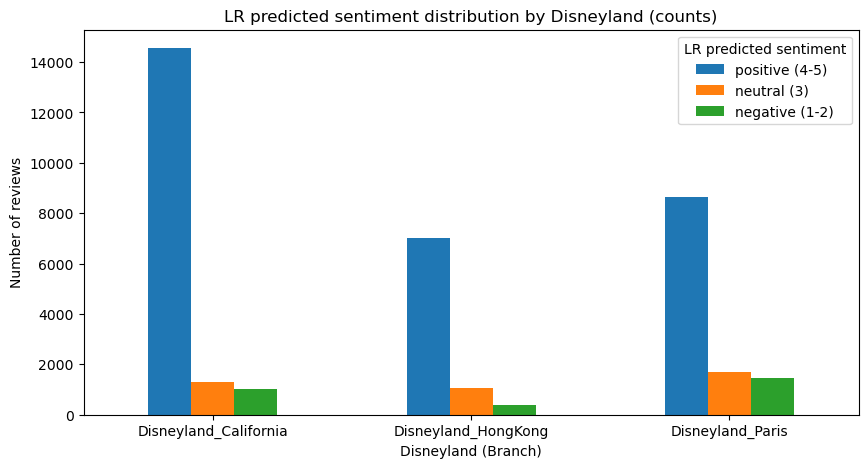

In [107]:
sent_order = ["positive (4-5)", "neutral (3)", "negative (1-2)"]
branch_order = ["Disneyland_California", "Disneyland_HongKong", "Disneyland_Paris"]

# Counts
sent_counts = (
    df.groupby(["Branch", "lr_pred"])
      .size()
      .reset_index(name="count")
)

sent_counts = sent_counts.pivot(index="Branch", columns="lr_pred", values="count").fillna(0)
sent_counts = sent_counts.reindex(index=branch_order, columns=sent_order, fill_value=0)

display(sent_counts)

# Plot
ax = sent_counts.plot(kind="bar", figsize=(10,5))
plt.title("LR predicted sentiment distribution by Disneyland (counts)")
plt.xlabel("Disneyland (Branch)")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.legend(title="LR predicted sentiment")
plt.show()


The Logistic Regression predictions confirm the pattern observed earlier in the project: positive sentiment dominates across all three parks, which is consistent with the overall class imbalance in the dataset (most reviews are rated 4–5). At the same time, the model highlights meaningful cross-location differences in how often neutral and negative sentiment appears.

In particular, Disneyland Paris stands out with a noticeably larger share of non-positive reviews (both neutral and negative) compared to the other locations, while Hong Kong shows the lowest share of negative predictions and a relatively higher neutral share. California remains strongly skewed toward positive reviews. This aligns with the earlier descriptive results in the notebook: the overall positivity holds everywhere, but the mix of sentiment classes differs by location.

Crucially, these differences become more informative once we move beyond counts and examine what people praise or complain about in each park. Therefore, the next step focuses on extracting the most characteristic terms for negative and positive reviews per location - because location-specific patterns are often driven less by “how positive” reviews are overall, and more by which issues dominate (e.g., queue/waiting language, crowding, price/value, or park-specific features).

### 7.2 Negative distinctive terms by Disneyland

In [109]:
TOP_N = 15
TARGET_SENT = "negative (1-2)"
branch_order = ["Disneyland_California", "Disneyland_HongKong", "Disneyland_Paris"]

feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
neg_top_terms_all = []

for br in branch_order:
    subset = df[(df["Branch"] == br) & (df["lr_pred"] == TARGET_SENT)].copy()
    texts = subset["text_tfidf"].fillna("").astype(str)

    if len(texts) == 0:
        continue

    X = tfidf_vectorizer.transform(texts)

    # mean TF-IDF per feature (group-level)
    mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
    top_idx = np.argsort(mean_tfidf)[::-1][:TOP_N]

    top_terms = pd.DataFrame({
        "Branch": br,
        "term": feature_names[top_idx],
        "mean_tfidf": mean_tfidf[top_idx]
    })

    neg_top_terms_all.append(top_terms)

neg_top_terms_df = pd.concat(neg_top_terms_all, ignore_index=True)



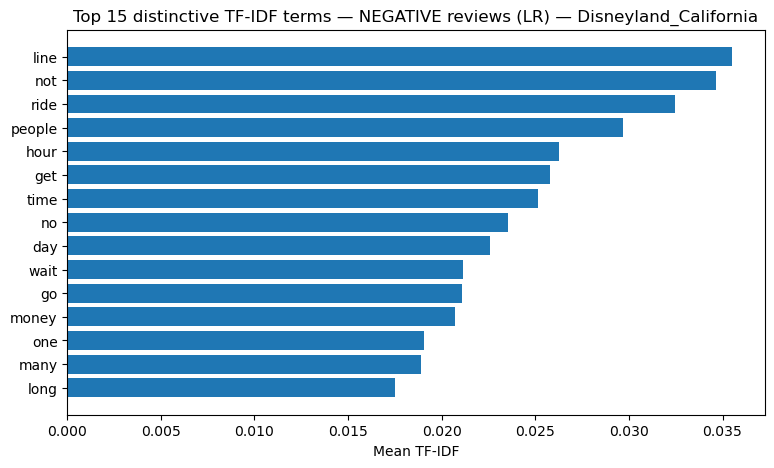

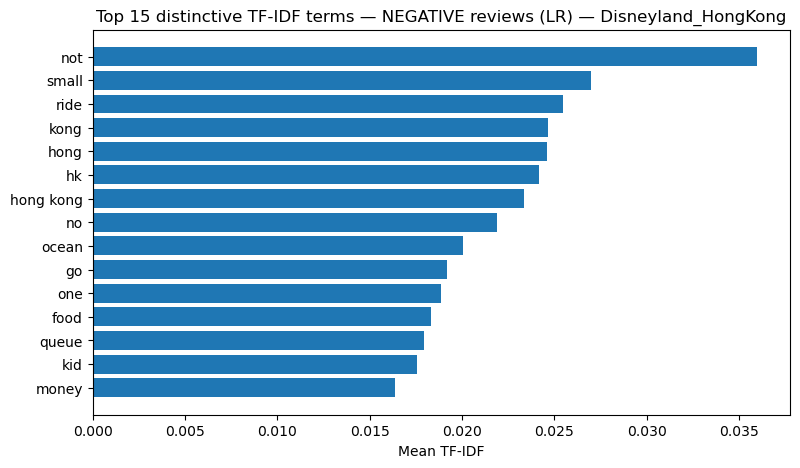

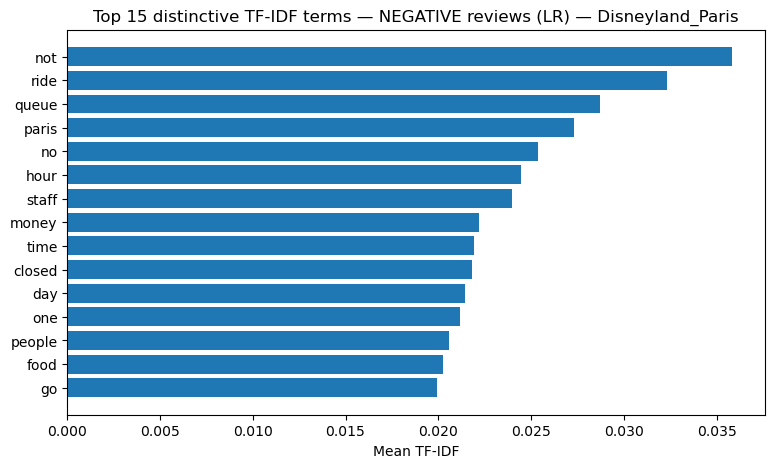

In [110]:
for br in branch_order:
    tmp = neg_top_terms_df[neg_top_terms_df["Branch"] == br].sort_values("mean_tfidf", ascending=True)
    plt.figure(figsize=(9,5))
    plt.barh(tmp["term"], tmp["mean_tfidf"])
    plt.title(f"Top {TOP_N} distinctive TF-IDF terms - NEGATIVE reviews (LR) - {br}")
    plt.xlabel("Mean TF-IDF")
    plt.ylabel("")
    plt.show()


Across all three locations, the negative vocabulary overlaps heavily: terms like “not”, “ride”, “people”, and time/queue-related words appear repeatedly, which suggests that dissatisfaction is often driven by broadly similar pain points (waiting, crowding, and ride experience) rather than entirely location-specific issues. At the same time, each park shows a small set of more distinctive cues that hint at different “flavours” of negative experiences.

For Disneyland California, the strongest signals are operational/friction terms such as “line”, “hour”, “wait”, and “time”, which points to complaints concentrated around queueing and time cost (long waits, pacing of the day, crowd pressure). Disneyland Paris also contains queueing/time language, but additionally shows “staff” and “closed”, suggesting that negative reviews there more often mention service interactions and ride/attraction closures alongside waiting. Disneyland Hong Kong stands out with location-specific tokens like “hk”, “hong kong”, and “ocean”, and the presence of “small” is much more prominent, indicating that complaints are more tied to park size/scale and context-specific references than in the other branches.

Finally, it’s worth noting that this TF-IDF ranking is still influenced by high-frequency “structural” words (e.g., not/no/go/get/one) that are not very informative on their own. In the next step we remove some of these generic terms specifically for interpretability-focused visuals (e.g., wordclouds per location), so the patterns become clearer and more descriptive of what visitors actually complain about in each park.

### 7.3 Wordclouds for negative predicted sentiment (LR) by location 

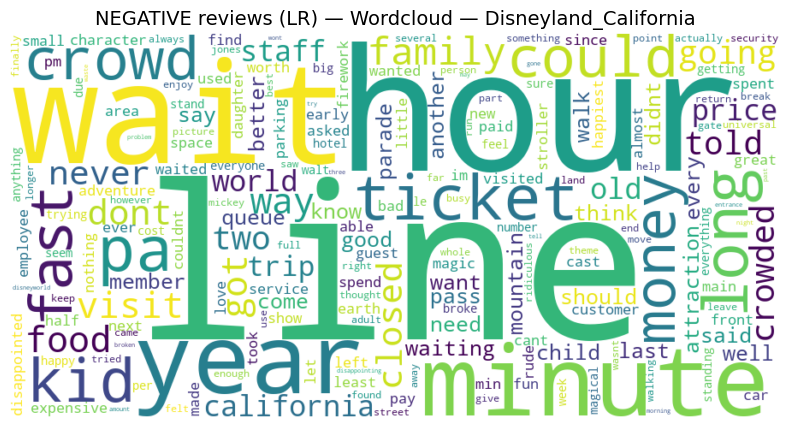

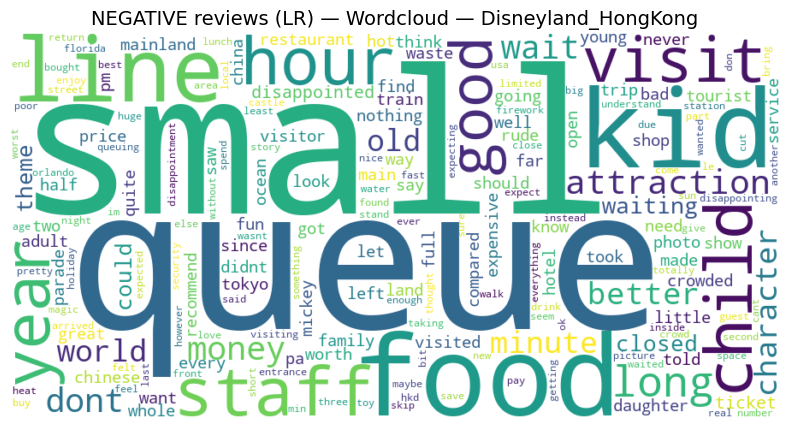

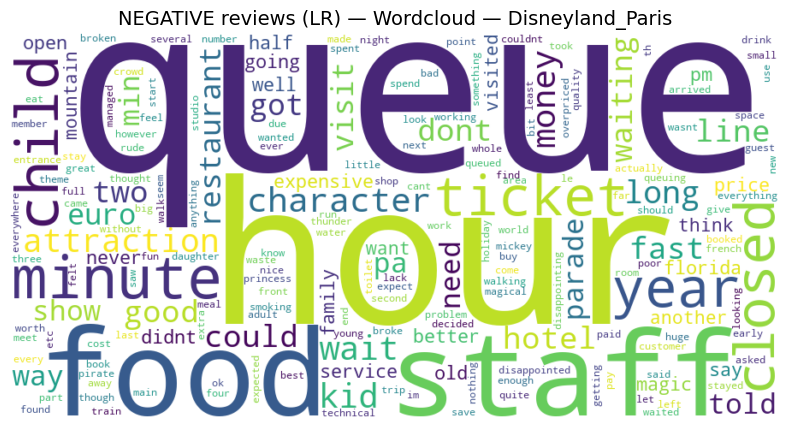

In [116]:
branch_order = ["Disneyland_California", "Disneyland_HongKong", "Disneyland_Paris"]

# Extra words to remove ONLY for visualization 
viz_stopwords = {"wa","ha","ll","ve","re","m","d","o","y","t","u","one","get","go","went","make","take","see","like",
                 "really","much","many", "even","also","still","back","around","first","place","people","experience",
                 "thing","lot","hk","hong","kong","paris", "ride", "no","not"}

viz_stopwords |= {"is", "are", "was", "were", "be", "been", "being", "have", "had", "it", "time","day"}

def make_wordcloud_from_text(text, extra_stopwords=None, title=""):
    if extra_stopwords is None:
        extra_stopwords = set()

    wc = WordCloud(
        width=900,
        height=450,
        background_color="white",
        collocations=False,   
        stopwords=extra_stopwords
    ).generate(text)

    plt.figure(figsize=(11,5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=14)
    plt.show()

for br in branch_order:
    subset = df[(df["Branch"] == br) & (df["lr_pred"] == "negative (1-2)")]
    text = " ".join(subset["text_tfidf"].fillna("").astype(str).tolist()).strip()

    if len(text) == 0:
        print(f"No negative reviews found for: {br}")
        continue

    make_wordcloud_from_text(
        text,
        extra_stopwords=viz_stopwords,
        title=f"NEGATIVE reviews (LR) - Wordcloud - {br}"
    )


Despite a common negative “backbone” across all parks (complaints about operational friction such as waiting, crowding, and service-related issues), the wordclouds suggest that the emphasis of negative experiences differs by location.


**Disneyland California:** Negative reviews concentrate strongly on waiting-related frustration (wait, hour, line) and crowd pressure, often paired with mentions of pricing/value (price). This points to an experience where dissatisfaction is frequently driven by time-cost tradeoffs (long waits relative to perceived value), rather than one single attraction-specific issue.


**Disneyland Hong Kong:** The most distinctive signal is park scale and expectations, with terms such as small standing out clearly. Complaints also include service and food-related aspects (staff, food), which suggests that negative sentiment here may be shaped more by comparisons to other parks (size, variety) and by supporting services, rather than only queue intensity.


**Disneyland Paris:** Negative reviews appear more tied to logistical/operational constraints, including ticket, euro, and hotel, alongside waiting-language (minute, line) and service cues (told, said, staff). This pattern is consistent with dissatisfaction arising from cost transparency, policies, and trip organization, i.e., problems around planning and “value for money” rather than only the park’s core attractions.


Overall, these cross-location patterns support RQ2: while positivity dominates in all parks, the drivers of negative sentiment are not identical - California is more “capacity/queues,” Hong Kong more “size/expectations + services,” and Paris more “pricing/policies + trip logistics.”

### 7.4  Positive top terms by Disneyland (Top 15, TF-IDF mean)

In [112]:
TOP_N = 15
TARGET_SENT = "positive (4-5)"
branch_order = ["Disneyland_California", "Disneyland_HongKong", "Disneyland_Paris"]

feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

pos_top_terms_all = []

for br in branch_order:
    subset = df[(df["Branch"] == br) & (df["lr_pred"] == TARGET_SENT)].copy()
    texts = subset["text_tfidf"].fillna("").astype(str)

    if len(texts) == 0:
        continue

    X = tfidf_vectorizer.transform(texts)
    mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
    top_idx = np.argsort(mean_tfidf)[::-1][:TOP_N]

    top_terms = pd.DataFrame({
        "Branch": br,
        "term": feature_names[top_idx],
        "mean_tfidf": mean_tfidf[top_idx]
    })

    pos_top_terms_all.append(top_terms)

pos_top_terms_df = pd.concat(pos_top_terms_all, ignore_index=True)



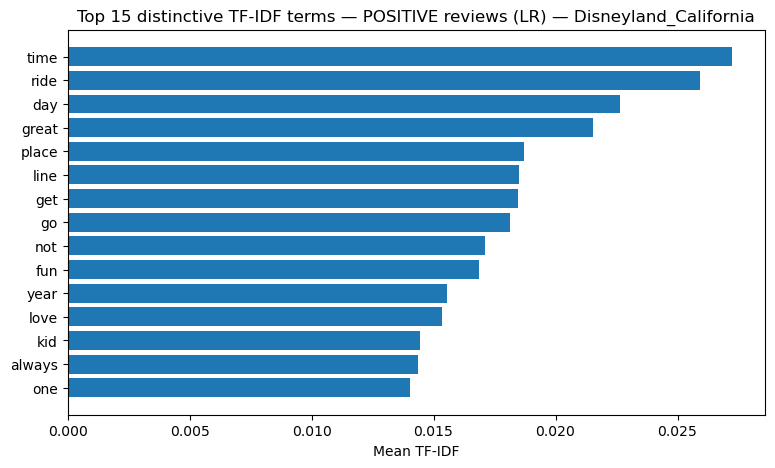

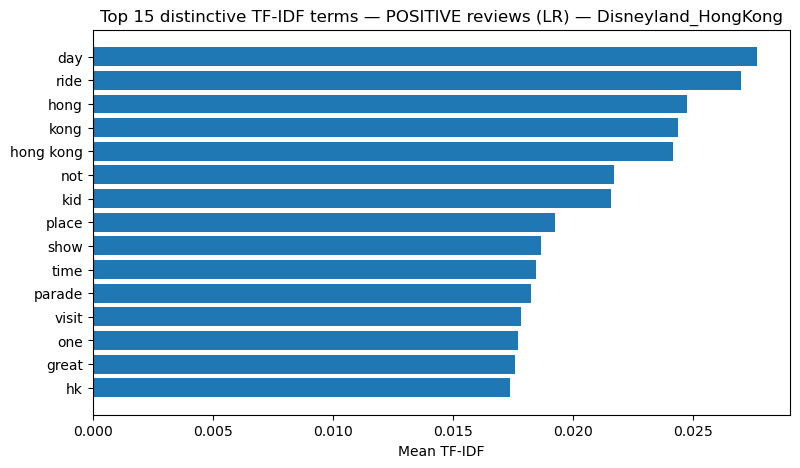

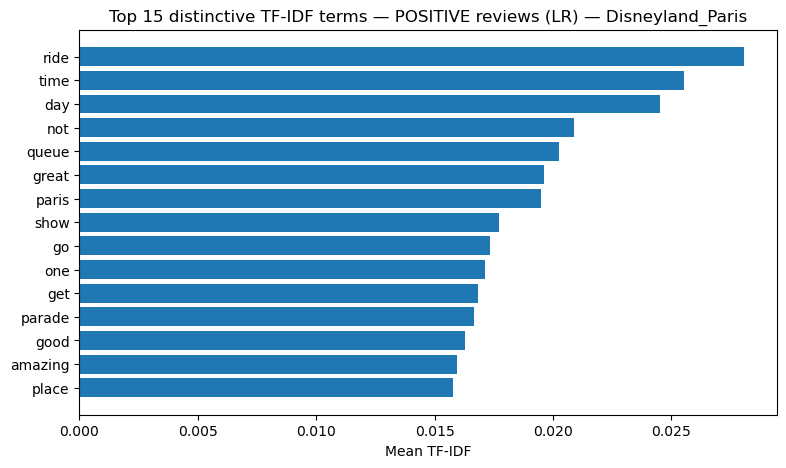

In [113]:
for br in branch_order:
    tmp = pos_top_terms_df[pos_top_terms_df["Branch"] == br].sort_values("mean_tfidf", ascending=True)
    plt.figure(figsize=(9,5))
    plt.barh(tmp["term"], tmp["mean_tfidf"])
    plt.title(f"Top {TOP_N} distinctive TF-IDF terms - POSITIVE reviews (LR) - {br}")
    plt.xlabel("Mean TF-IDF")
    plt.ylabel("")
    plt.show()


Across all parks, positive reviews share a common “core” vocabulary (e.g., ride, day, time, great, fun), which is expected given the shared theme-park experience. However, TF-IDF still reveals meaningful differences in what is most characteristic of positive sentiment in each location.

For California, the signal is strongly ride- and experience-driven (ride, great, fun, love), consistent with visitors describing the park in terms of attractions and overall enjoyment. 

Hong Kong shows a clearer “place identity” component (hong/kong/hk alongside show, parade, visit), suggesting that positive reviews more often frame the experience as a destination-specific highlight rather than purely ride-focused.

In Paris, queue still appears among positive distinctive terms, which is informative: it suggests that even satisfied visitors often discuss queues (e.g., managing waits, using systems effectively), so crowding/throughput is a central theme regardless of sentiment, not only a complaint driver.

Taken together, the positive TF-IDF profiles indicate that “what people praise” is broadly similar (rides and enjoyment), but the storytelling emphasis differs: California leans toward attractions and fun, Hong Kong toward location identity and shows, and Paris toward the “experience under constraints” (including queue management), reinforcing cross-location variation in sentiment narratives.

## 8. Summary and conclusions

In this project, we aimed to quantify and compare sentiment in Disneyland visitor reviews across locations, using star ratings as a proxy for sentiment labels (negative 1–2, neutral 3, positive 4–5) and a consistent preprocessing + TF-IDF representation to make results comparable. The workflow combined exploratory corpus inspection (wordclouds, n-grams), feature engineering (TF-IDF with filtering to reduce noise while preserving informative terms such as negations), and multiple sentiment approaches: lexicon-based baselines (e.g., VADER), a transformer-based model (BERT, 3-class), and supervised classifiers trained on the labeled data. 

Overall, the purpose was achieved: supervised models performed best on this dataset, and Logistic Regression provided the most reliable balance across classes under label imbalance, which is why we prioritize weighted F1 (not only accuracy) as the main selection criterion. We also examined key practical assumptions and their implications - most importantly, that ratings approximate sentiment and that the dataset is strongly skewed toward positive reviews - by analyzing confusion matrices and error cases, which showed that mixed/complaint-heavy narratives inside high-star reviews (and occasional positive phrases inside low-star complaints) can mislead the model. 

Finally, cross-location comparisons indicate that sentiment patterns are not identical across parks: while positivity dominates everywhere, the content behind negative and positive predictions differs by branch, as reflected in location-specific distinctive terms and wordclouds (e.g., queue/waiting, price/value, size/crowding). Taken together, the results support a clear conclusion: sentiment in reviews is structured, learnable from text, and meaningfully heterogeneous across locations - especially in what visitors praise and complain about - while neutral sentiment remains the most challenging class due to its linguistic overlap with both positive and negative reviews.